In [1]:
# Imports
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Load FRED monthly series from Triple 1
DATA_DIR = Path("data") / "Triple 1"  # relative to RecPlay/, where this notebook lives

def load_csv(name: str) -> pd.Series:
    df = pd.read_csv(DATA_DIR / f"{name}.csv", parse_dates=["observation_date"], index_col="observation_date")
    return df[name].astype(float)

cpi = load_csv("CPIAUCSL")
unrate = load_csv("UNRATE")
fedfunds = load_csv("FEDFUNDS")

for s in (cpi, unrate, fedfunds):
    print(f"{s.name:9s} {s.index.min().date()} to {s.index.max().date()}  n={len(s)}  missing={s.isna().sum()}")

CPIAUCSL  1947-01-01 to 2026-09-01  n=957  missing=1
UNRATE    1948-01-01 to 2026-09-01  n=945  missing=1
FEDFUNDS  1954-07-01 to 2026-09-01  n=867  missing=0


In [3]:
# Impute October 2025 as Bureau of labor stats did not collect CPI or household-survey data during the shutdown

cpi_m, unrate_m, fedfunds_m = (s.asfreq("MS") for s in (cpi, unrate, fedfunds))

cpi_imputed = cpi_m.isna()
unrate_imputed = unrate_m.isna()

print("Imputing CPI at:", list(cpi_m.index[cpi_imputed].date))
print("Imputing UNRATE at:", list(unrate_m.index[unrate_imputed].date))
assert not fedfunds_m.isna().any()

cpi_clean = np.exp(np.log(cpi_m).interpolate(method="linear", limit_area="inside"))  # geometric for a price level
unrate_clean = unrate_m.interpolate(method="linear", limit_area="inside")
fedfunds_clean = fedfunds_m

print(pd.DataFrame({"CPIAUCSL": cpi_clean, "UNRATE": unrate_clean}).loc["2025-09":"2025-11"])

Imputing CPI at: [datetime.date(2025, 10, 1)]
Imputing UNRATE at: [datetime.date(2025, 10, 1)]
                    CPIAUCSL  UNRATE
observation_date                    
2025-09-01        324.245000    4.40
2025-10-01        324.653742    4.45
2025-11-01        325.063000    4.50


In [4]:
# CPI level turned to YoY inflation, on the full CPI history (1947-), thus no lost months at the 1954 start
# YoY inflation instead of MoM inflation, avoiding overly noisy periods 
inflation = (100 * (np.log(cpi_clean) - np.log(cpi_clean.shift(12)))).rename("INFLATION")

# A YoY value is imputed if either of its two CPI inputs was imputed
inflation_imputed = cpi_imputed | cpi_imputed.shift(12, fill_value=False)

inflation = inflation.dropna()
inflation_imputed = inflation_imputed.loc[inflation.index]
print(f"INFLATION {inflation.index.min().date()} to {inflation.index.max().date()}  n={len(inflation)}")

INFLATION 1948-01-01 to 2026-09-01  n=945


In [5]:
# Common window, checks
macro = pd.concat([inflation, unrate_clean, fedfunds_clean], axis=1, join="inner")
macro["IMPUTED"] = (inflation_imputed | unrate_imputed).loc[macro.index]

assert macro.index.is_monotonic_increasing and macro.index.is_unique
assert len(macro.asfreq("MS")) == len(macro), "gap in monthly index"
assert not macro.isna().any().any(), "NaN left after cleaning"

print(f"{macro.index.min().date()} to {macro.index.max().date()}  n={len(macro)}")
print("Imputed rows:", list(macro.index[macro["IMPUTED"]].date))
macro.head()

1954-07-01 to 2026-09-01  n=867
Imputed rows: [datetime.date(2025, 10, 1)]


,INFLATION,UNRATE,FEDFUNDS,IMPUTED
observation_date,,,,
1954-07-01,0.260951,5.8,0.80,False
1954-08-01,0.000000,6.0,1.22,False
1954-09-01,-0.297952,6.1,1.07,False
1954-10-01,-0.857095,5.7,0.85,False
1954-11-01,-0.261048,5.3,0.83,False


                min    min_date       max    max_date
INFLATION -1.978199  2009-07-01  13.62102  1980-03-01
UNRATE     3.400000  1968-09-01  14.80000  2020-04-01
FEDFUNDS   0.050000  2020-04-01  19.10000  1981-06-01


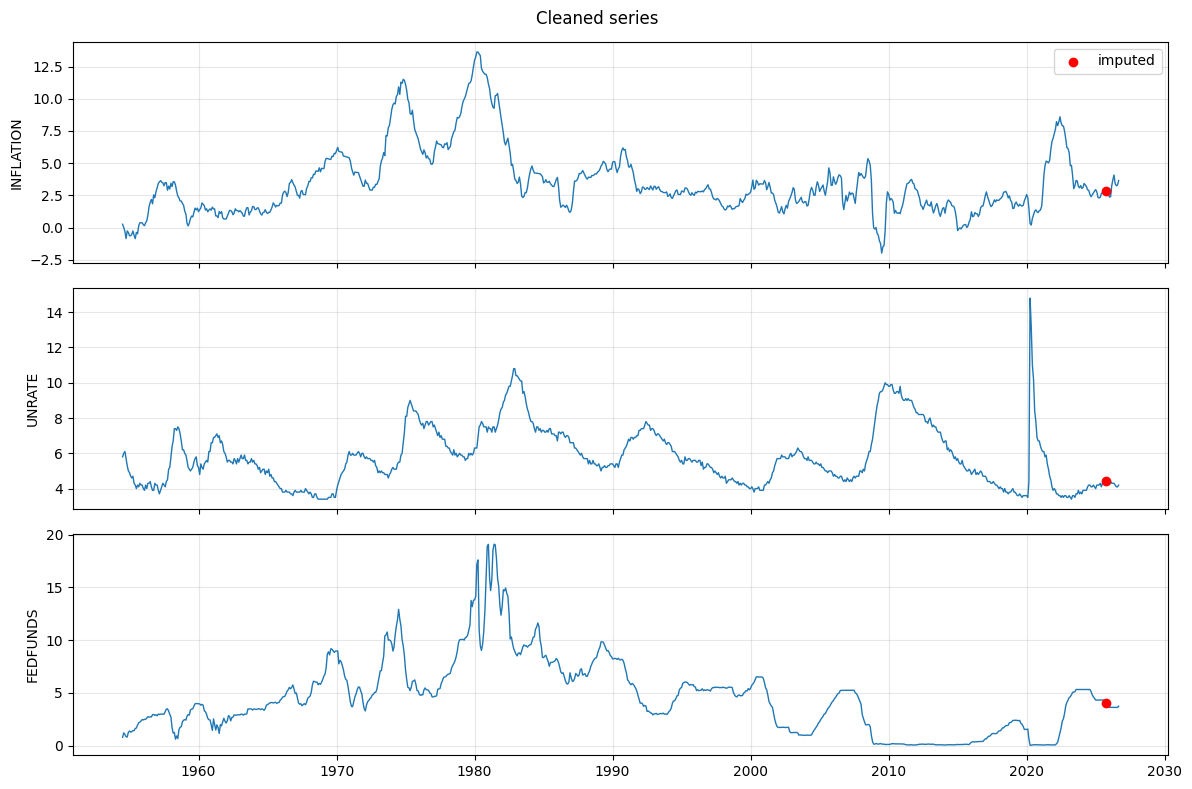

In [6]:
## We report extremes as well.

series_cols = ["INFLATION", "UNRATE", "FEDFUNDS"]
extremes = pd.DataFrame({
    "min": macro[series_cols].min(),
    "min_date": macro[series_cols].idxmin().dt.date,
    "max": macro[series_cols].max(),
    "max_date": macro[series_cols].idxmax().dt.date,
})
print(extremes)

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for ax, col in zip(axes, series_cols):
    ax.plot(macro.index, macro[col], lw=1)
    ax.scatter(macro.index[macro["IMPUTED"]], macro.loc[macro["IMPUTED"], col], color="red", zorder=3, label="imputed")
    ax.set_ylabel(col)
    ax.grid(alpha=0.3)
axes[0].legend(loc="upper right")
fig.suptitle("Cleaned series")
fig.tight_layout()
plt.show()

In [7]:
# Recurrence plot setup: Euclidean distance on z-scored, delay-embedded series over the full 1954-2026 window.
# The threshold is set per series by a fixed recurrence rate, so the three RPs are equally dense
# despite having different units and ranges.
from matplotlib import dates as mdates

M, TAU = 1, 1      # embedding dimension and delay (months); m = 1 means the state is the value itself
RR_TARGET = 0.10   # share of off-diagonal pairs counted as recurrent

def embed(x: np.ndarray, m: int, tau: int) -> np.ndarray:
    n = len(x) - (m - 1) * tau
    return np.column_stack([x[i * tau : i * tau + n] for i in range(m)])

def recurrence(series: pd.Series, m: int = M, tau: int = TAU, rr: float = RR_TARGET):
    x = series.to_numpy(dtype=float)
    X = embed((x - x.mean()) / x.std(), m, tau)
    D = np.sqrt(((X[:, None, :] - X[None, :, :]) ** 2).sum(axis=-1))
    upper = np.triu_indices(len(D), k=1)
    eps = np.quantile(D[upper], rr)
    R = D <= eps
    dates = series.index[(m - 1) * tau :]  # each embedded state is dated by its latest month
    return D, R, eps, dates

def format_date_axes(a) -> None:
    for axis in (a.xaxis, a.yaxis):
        axis.set_major_locator(mdates.YearLocator(10))
        axis.set_major_formatter(mdates.DateFormatter("%Y"))
    a.set_xlabel("month j")
    a.set_ylabel("month i")

def plot_rp(series: pd.Series, m: int = M, tau: int = TAU, rr: float = RR_TARGET) -> np.ndarray:
    D, R, eps, dates = recurrence(series, m, tau, rr)
    actual_rr = R[np.triu_indices(len(R), k=1)].mean()  # ties at eps can push this above the target
    t0, t1 = mdates.date2num(dates[0]), mdates.date2num(dates[-1])
    extent = (t0, t1, t0, t1)

    fig, ax = plt.subplots(1, 2, figsize=(14, 6.5))
    im = ax[0].imshow(D, cmap="gist_earth", origin="lower", interpolation="nearest", extent=extent)
    fig.colorbar(im, ax=ax[0], fraction=0.046, pad=0.04, label="distance (std units)")
    ax[0].set_title("Distance matrix")
    ax[1].imshow(R, cmap="copper", origin="lower", interpolation="nearest", extent=extent)
    ax[1].set_title(f"Recurrence plot, ε = {eps:.3f} (RR = {actual_rr:.3f})")
    for a in ax:
        format_date_axes(a)
    fig.suptitle(f"{series.name}: EucD, m = {m}, τ = {tau}, {dates[0]:%Y-%m} to {dates[-1]:%Y-%m}, n = {len(dates)}")
    fig.tight_layout()
    plt.show()
    return R

rps = {}

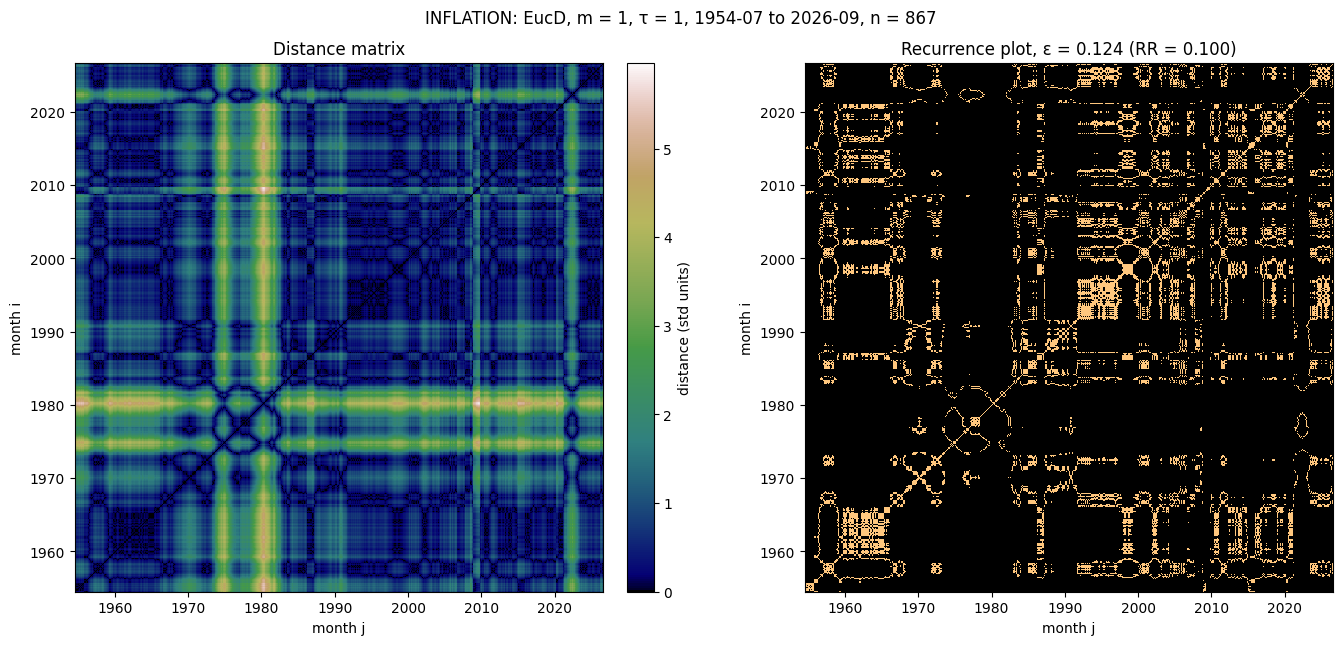

In [8]:
# Inflation RP
rps["INFLATION"] = plot_rp(macro["INFLATION"])

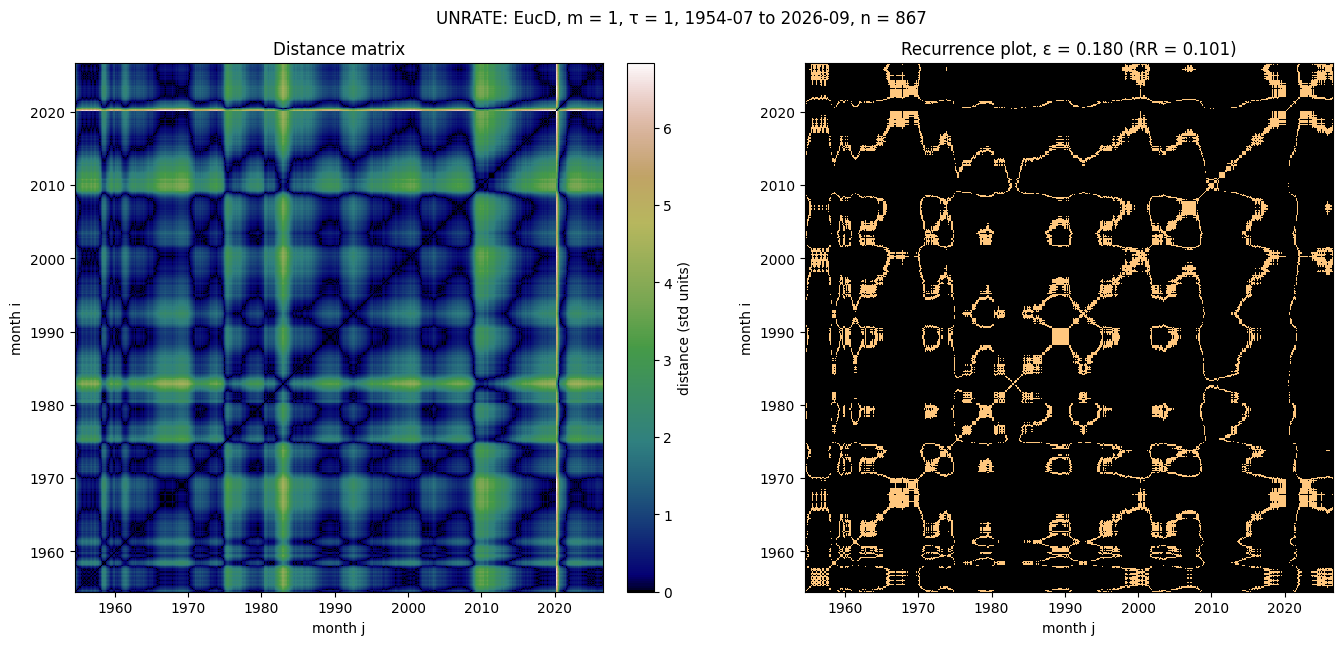

In [9]:
# Unemployment RP
rps["UNRATE"] = plot_rp(macro["UNRATE"])

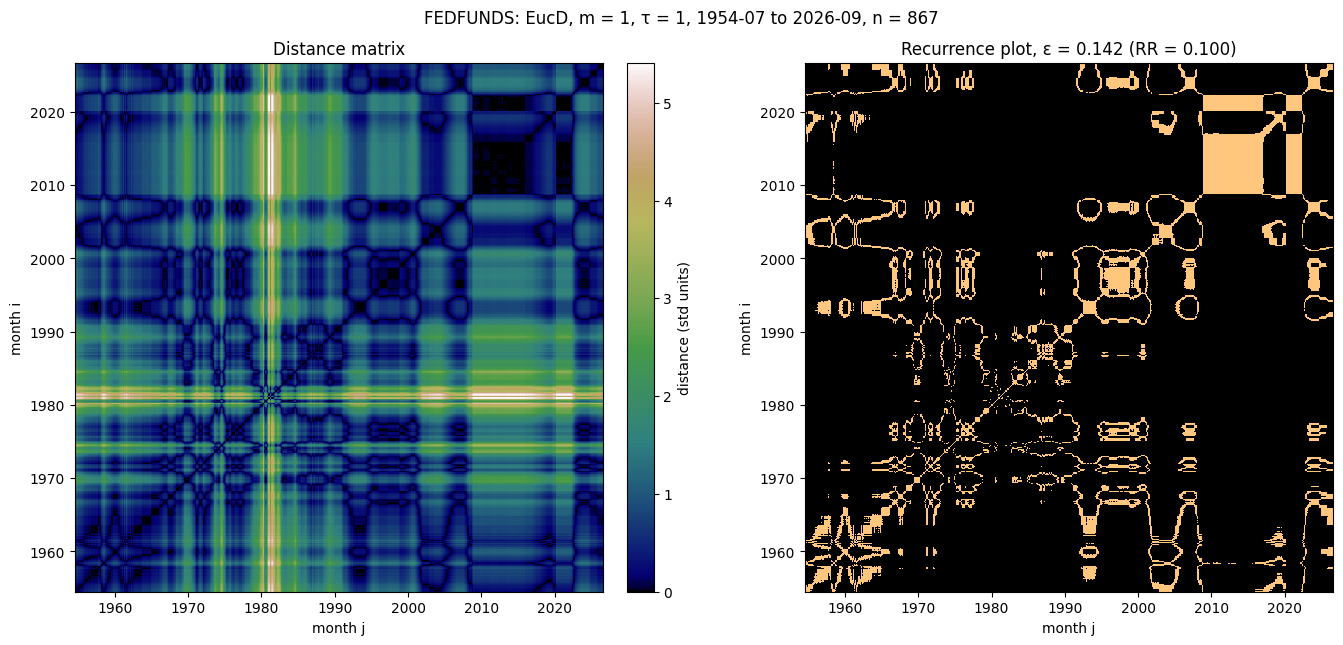

In [10]:
# Fed funds RP
rps["FEDFUNDS"] = plot_rp(macro["FEDFUNDS"])

In [11]:
# Recurrence independence, per pair and for the trio.
# If the series recurred independently, a month pair (i, j) would be jointly recurrent with probability
# equal to the product of the individual recurrence rates. ratio = observed joint RR / that product
# (1 = no more co-recurrence than chance; > 1 = they revisit their past states together).
from itertools import combinations

N_STATES = len(macro) - (M - 1) * TAU
COMBOS = [combo for k in (2, 3) for combo in combinations(series_cols, k)]  # 3 pairs + the trio

def independence_table(min_sep: int = 1) -> pd.DataFrame:
    """Joint vs expected RR, counted over month pairs (i, j) with j - i >= min_sep."""
    idx = np.triu_indices(N_STATES, k=min_sep)
    rr = {c: rps[c][idx].mean() for c in series_cols}
    rows = []
    for combo in COMBOS:
        joint_rr = np.logical_and.reduce([rps[c] for c in combo])[idx].mean()
        expected_rr = np.prod([rr[c] for c in combo])
        rows.append({"systems": " × ".join(combo),
                     **{f"RR {c}": rr[c] for c in combo},
                     "joint RR": joint_rr,
                     "expected if independent": expected_rr,
                     "ratio": joint_rr / expected_rr})
    table = pd.DataFrame(rows).set_index("systems")
    return table[[f"RR {c}" for c in series_cols] + ["joint RR", "expected if independent", "ratio"]]

independence = independence_table()  # all off-diagonal pairs
independence

,RR INFLATION,RR UNRATE,RR FEDFUNDS,joint RR,expected if independent,ratio
systems,,,,,,
INFLATION × UNRATE,0.100002,0.10082,NaN,0.013902,0.010082,1.378867
INFLATION × FEDFUNDS,0.100002,NaN,0.10001,0.016736,0.010001,1.673418
UNRATE × FEDFUNDS,NaN,0.10082,0.10001,0.014118,0.010083,1.400156
INFLATION × UNRATE × FEDFUNDS,0.100002,0.10082,0.10001,0.004840,0.001008,4.800041


In [12]:
# Theiler window: drop month pairs closer than THEILER months apart.
# Each series is smooth, so neighbouring months recur in all of them at once; that band says nothing about
# a link between the series. Both the individual and the joint RRs are recomputed on the remaining pairs.
THEILER = 12

independence_theiler = independence_table(min_sep=THEILER)
independence_theiler

,RR INFLATION,RR UNRATE,RR FEDFUNDS,joint RR,expected if independent,ratio
systems,,,,,,
INFLATION × UNRATE,0.093622,0.091212,NaN,0.008988,0.008539,1.052510
INFLATION × FEDFUNDS,0.093622,NaN,0.089091,0.011491,0.008341,1.377667
UNRATE × FEDFUNDS,NaN,0.091212,0.089091,0.007048,0.008126,0.867275
INFLATION × UNRATE × FEDFUNDS,0.093622,0.091212,0.089091,0.001175,0.000761,1.544530


In [13]:
# Doubly and triply joint covariance and correlation of the recurrence indicators.
# Each month pair (i, j) is one observation; R_X[i, j] is a 0/1 variable with mean q_X = RR_X.
#
# Pairs (2nd order):
#   Cov_XY  = E[(R_X - q_X)(R_Y - q_Y)] = q_XY - q_X q_Y                (joint RR minus its independence value)
#   corr_XY = Cov_XY / (σ_X σ_Y),  σ_X = sqrt(q_X (1 - q_X))           (phi coefficient, in [-1, 1])
#
# Trio (3rd-order joint cumulant):
#   Cov_XYZ = E[(R_X - q_X)(R_Y - q_Y)(R_Z - q_Z)]
#           = q_XYZ - q_X q_YZ - q_Y q_XZ - q_Z q_XY + 2 q_X q_Y q_Z
#   It is 0 whenever one series is independent of the other two, even if those two are linked, so it isolates
#   the purely three-way part (unlike D_3 = q_XYZ - q_X q_Y q_Z in ResearchBook).
#   corr_XYZ = Cov_XYZ / (‖R_X - q_X‖₃ ‖R_Y - q_Y‖₃ ‖R_Z - q_Z‖₃),  ‖a‖₃ = E[|a|³]^(1/3).
#   Hölder's inequality bounds this in [-1, 1]. Dividing by σ_X σ_Y σ_Z (standard coskewness) is not bounded
#   here: with q ≈ 0.1 the indicators are very skewed and that ratio can exceed 1.

def dependence_table(min_sep: int = 1) -> pd.DataFrame:
    """Joint covariance / correlation over month pairs (i, j) with j - i >= min_sep."""
    idx = np.triu_indices(N_STATES, k=min_sep)
    centred = {c: rps[c][idx] - rps[c][idx].mean() for c in series_cols}
    rows = []
    for combo in COMBOS:
        parts = [centred[c] for c in combo]
        cov = np.prod(parts, axis=0).mean()
        if len(combo) == 2:
            scale = np.prod([np.sqrt(np.mean(p ** 2)) for p in parts])
        else:
            scale = np.prod([np.mean(np.abs(p) ** 3) ** (1 / 3) for p in parts])
        rows.append({"systems": " × ".join(combo), "order": len(combo),
                     "joint covariance": cov, "joint correlation": cov / scale})
    return pd.DataFrame(rows).set_index("systems")

dependence = dependence_table()                         # all off-diagonal pairs
dependence_theiler = dependence_table(min_sep=THEILER)  # pairs at least THEILER months apart
pd.concat({"all pairs": dependence.drop(columns="order"),
           f"Theiler {THEILER}": dependence_theiler.drop(columns="order")}, axis=1)

all pairs                    \
                              joint covariance joint correlation   
systems                                                            
INFLATION × UNRATE                    0.003820          0.042288   
INFLATION × FEDFUNDS                  0.006735          0.074830   
UNRATE × FEDFUNDS                     0.004035          0.044667   
INFLATION × UNRATE × FEDFUNDS         0.002367          0.032014   

                                    Theiler 12                    
                              joint covariance joint correlation  
systems                                                           
INFLATION × UNRATE                    0.000448          0.005346  
INFLATION × FEDFUNDS                  0.003150          0.037960  
UNRATE × FEDFUNDS                    -0.001079         -0.013150  
INFLATION × UNRATE × FEDFUNDS         0.000188          0.002717

In [14]:
# # Time-shift surrogate test.
# # Rotating a series by s months rotates its RP along both axes: R_shifted[i, j] = R[i - s, j - s].
# # Its own recurrence structure (including the dense diagonal band) is kept, only its alignment with the
# # other series is broken. Over many shifts this gives the joint RR expected with no link but the same
# # autocorrelation; the observed joint RR is compared with that null distribution.
# MIN_SHIFT = 60        # months; shorter shifts could leave the series in the same business cycle
# N_TRIO_DRAWS = 1000   # random (s1, s2) shift combinations for the trio
# rng = np.random.default_rng(42)

# upper = np.triu_indices(N_STATES, k=1)
# valid_shifts = np.arange(MIN_SHIFT, N_STATES - MIN_SHIFT + 1)

# def shift_rp(R: np.ndarray, s: int) -> np.ndarray:
#     return np.roll(R, (s, s), axis=(0, 1))

# def joint_rr_of(mats) -> float:
#     return np.logical_and.reduce(mats)[upper].mean()

# rows = []
# for combo in COMBOS:
#     anchor, *others = combo  # the first series stays fixed, the others are shifted
#     observed = joint_rr_of([rps[c] for c in combo])
#     if len(others) == 1:
#         shift_sets = [(s,) for s in valid_shifts]  # every admissible shift
#     else:
#         shift_sets = []
#         while len(shift_sets) < N_TRIO_DRAWS:
#             s1, s2 = rng.choice(valid_shifts, size=2)
#             if MIN_SHIFT <= (s1 - s2) % N_STATES <= N_STATES - MIN_SHIFT:  # shifted series also misaligned with each other
#                 shift_sets.append((s1, s2))
#     null = np.array([joint_rr_of([rps[anchor]] + [shift_rp(rps[c], s) for c, s in zip(others, shifts)])
#                      for shifts in shift_sets])
#     rows.append({"systems": " × ".join(combo),
#                  "joint RR": observed,
#                  "null mean": null.mean(),
#                  "null 95%": np.quantile(null, 0.95),
#                  "ratio vs null": observed / null.mean(),
#                  "p-value": (1 + (null >= observed).sum()) / (1 + len(null)),
#                  "surrogates": len(null)})
# independence_shift = pd.DataFrame(rows).set_index("systems")
# independence_shift

In [15]:
# Pair RPs: joint recurrence. 
# Months (i, j) are jointly recurrent when BOTH series recur there: JR = R_X AND R_Y.
# Each series keeps its own ε from cell 6, so different units never get mixed in one distance.
# Cross RPs (X at month i vs Y at month j) are not used: they need both series in one shared state space.
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

OVERLAY_CMAP = ListedColormap(["black", "tab:blue", "tab:orange", "white"])

def plot_jrp(a: str, b: str) -> np.ndarray:
    Ra, Rb = rps[a], rps[b]
    JR = Ra & Rb
    stats = independence.loc[f"{a} × {b}"]
    dates = macro.index[(M - 1) * TAU :]
    t0, t1 = mdates.date2num(dates[0]), mdates.date2num(dates[-1])
    extent = (t0, t1, t0, t1)

    fig, ax = plt.subplots(1, 2, figsize=(14, 6.5))
    overlay = Ra.astype(int) + 2 * Rb.astype(int)  # 0 neither, 1 a only, 2 b only, 3 both
    ax[0].imshow(overlay, cmap=OVERLAY_CMAP, vmin=-0.5, vmax=3.5, origin="lower", interpolation="nearest", extent=extent)
    ax[0].legend(handles=[Patch(color="tab:blue", label=f"{a} only"),
                          Patch(color="tab:orange", label=f"{b} only"),
                          Patch(facecolor="white", edgecolor="grey", label="both")],
                 loc="upper left", fontsize=8, framealpha=0.9)
    ax[0].set_title("Individual RPs overlaid")
    ax[1].imshow(JR, cmap="copper", origin="lower", interpolation="nearest", extent=extent)
    ax[1].set_title(f"Joint recurrence plot, RR = {stats['joint RR']:.4f} ({stats['ratio']:.1f}× independence)")
    for x in ax:
        format_date_axes(x)
    fig.suptitle(f"{a} × {b}: EucD, m = {M}, τ = {TAU}, {dates[0]:%Y-%m} to {dates[-1]:%Y-%m}, n = {len(dates)}")
    fig.tight_layout()
    plt.show()
    return JR

jrps = {}

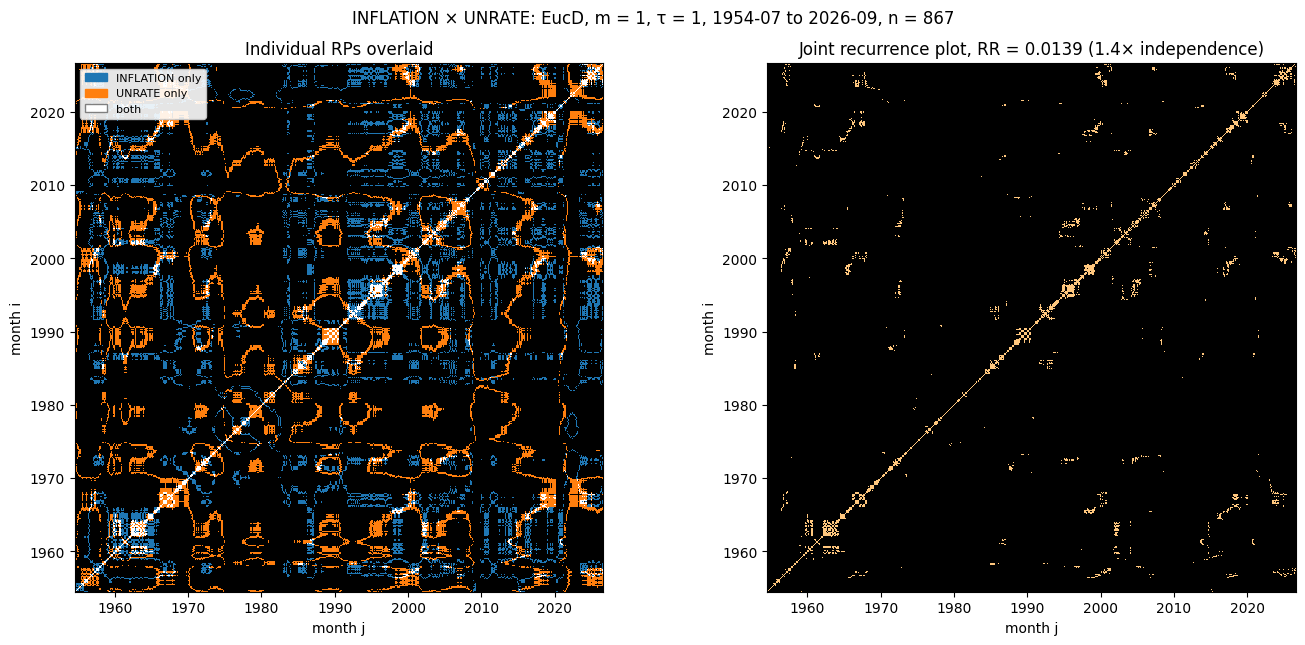

In [16]:
# Inflation x Unemployment JRP
jrps[("INFLATION", "UNRATE")] = plot_jrp("INFLATION", "UNRATE")

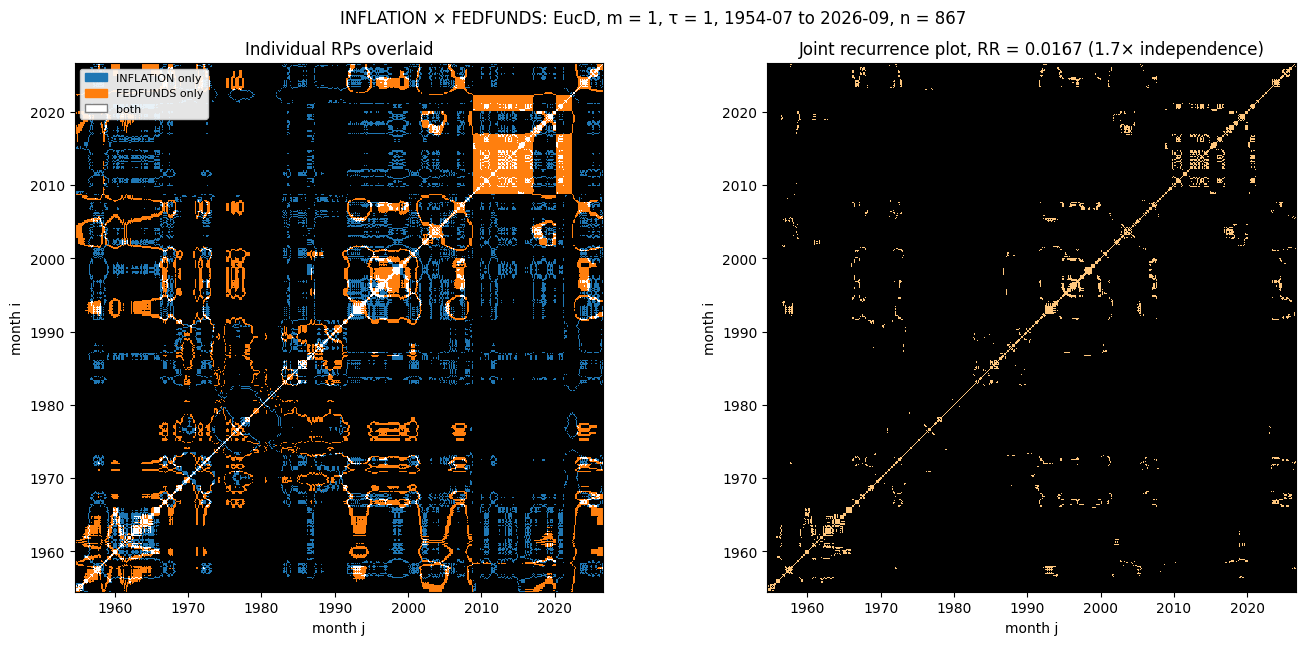

In [17]:
# Inflation x Fed funds JRP
jrps[("INFLATION", "FEDFUNDS")] = plot_jrp("INFLATION", "FEDFUNDS")

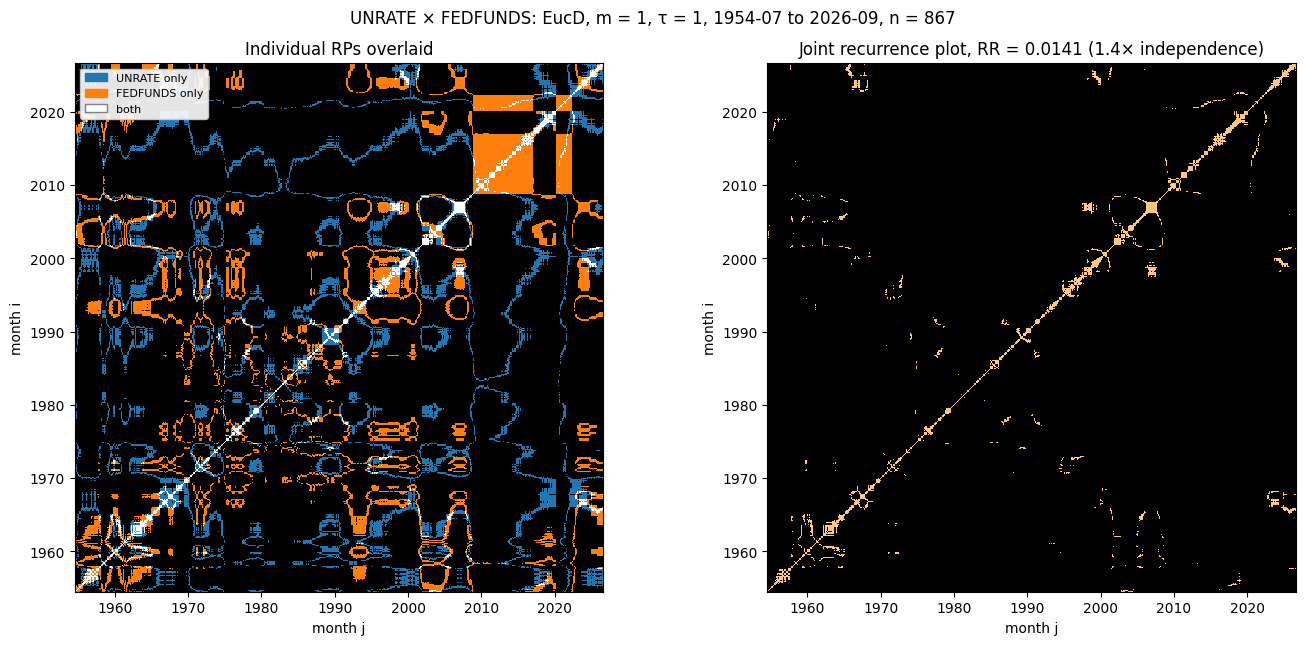

In [18]:
# Unemployment x Fed funds JRP
jrps[("UNRATE", "FEDFUNDS")] = plot_jrp("UNRATE", "FEDFUNDS")

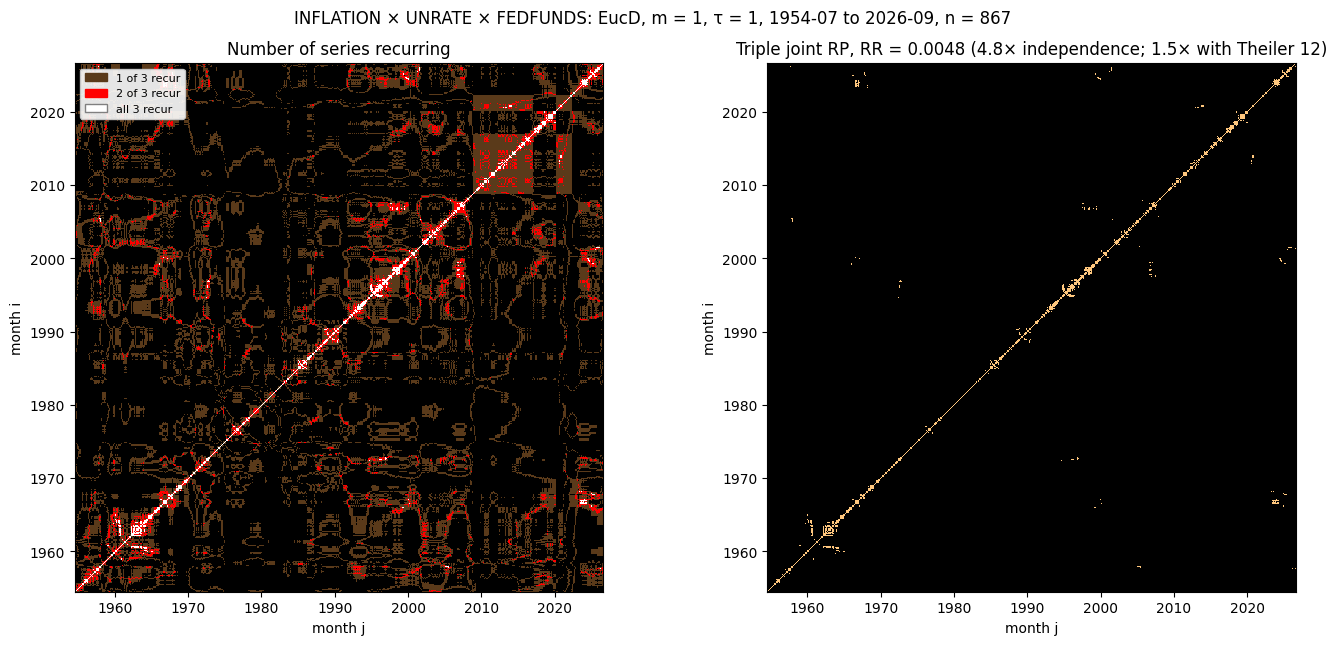

In [19]:
# Triple joint RP: months (i, j) are jointly recurrent only when ALL THREE series recur there:
# JR3 = R_INFLATION AND R_UNRATE AND R_FEDFUNDS. Each series keeps its own ε from cell 6.
COUNT_CMAP = ListedColormap(["black", "#5a3a1a", "red", "white"])  # 0, 1, 2, 3 series recurring

def plot_triple_jrp(a: str, b: str, c: str) -> np.ndarray:
    mats = [rps[a], rps[b], rps[c]]
    JR3 = np.logical_and.reduce(mats)
    key = f"{a} × {b} × {c}"
    stats, stats_theiler = independence.loc[key], independence_theiler.loc[key]
    dates = macro.index[(M - 1) * TAU :]
    t0, t1 = mdates.date2num(dates[0]), mdates.date2num(dates[-1])
    extent = (t0, t1, t0, t1)

    fig, ax = plt.subplots(1, 2, figsize=(14, 6.5))
    count = sum(R.astype(int) for R in mats)  # how many of the three series recur at (i, j)
    ax[0].imshow(count, cmap=COUNT_CMAP, vmin=-0.5, vmax=3.5, origin="lower", interpolation="nearest", extent=extent)
    ax[0].legend(handles=[Patch(color=COUNT_CMAP(k), label=f"{k} of 3 recur") for k in (1, 2)]
                         + [Patch(facecolor="white", edgecolor="grey", label="all 3 recur")],
                 loc="upper left", fontsize=8, framealpha=0.9)
    ax[0].set_title("Number of series recurring")
    ax[1].imshow(JR3, cmap="copper", origin="lower", interpolation="nearest", extent=extent)
    ax[1].set_title(f"Triple joint RP, RR = {stats['joint RR']:.4f} "
                    f"({stats['ratio']:.1f}× independence; {stats_theiler['ratio']:.1f}× with Theiler {THEILER})")
    for x in ax:
        format_date_axes(x)
    fig.suptitle(f"{key}: EucD, m = {M}, τ = {TAU}, {dates[0]:%Y-%m} to {dates[-1]:%Y-%m}, n = {len(dates)}")
    fig.tight_layout()
    plt.show()
    return JR3

jrp3 = plot_triple_jrp("INFLATION", "UNRATE", "FEDFUNDS")


## β-divergence: thresholded RPs only

For each **β = 1, 3, 7**, show three individual, three pairwise joint, and one triple joint RP. Reuse the cleaned monthly `macro` sample, embedding parameters `M`, `TAU`, and `RR_TARGET` from above. No divergence heatmaps or recurrence overlays are shown.

**Positive inputs:** inflation can be negative, so signed rates and z-scores cannot be used directly in the β = 1 logarithm. Encode each percentage-valued observation $v_t$ as $u_t=\exp(v_t/100)$. This is strictly positive and preserves ordering, including negative inflation, without absolute values or sample-dependent shifts. For the log-based inflation series it is the year-over-year CPI ratio. For unemployment and Fed funds it is only a monotone mathematical encoding, **not** a gross return, compounding formula, or probability. This representation differs from the z-scores in the Euclidean section; differences from those plots are not due to β alone.

**Symmetry:** use the mean of the forward and reverse β-divergences, summed across embedded coordinates:

$$
S_\beta(x,y)=\frac{d_\beta(x\Vert y)+d_\beta(y\Vert x)}{2}
=\begin{cases}
\frac12(x-y)(\log x-\log y),&\beta=1,\\
\frac{(x-y)(x^{\beta-1}-y^{\beta-1})}{2(\beta-1)},&\beta>1.
\end{cases}
$$

For each series and β, choose ε from the same off-diagonal upper-triangle quantile as before and threshold at $S_{\beta,ij}\leq\varepsilon$. Pairwise and triple RPs intersect the individual matrices without another threshold. Titles report actual off-diagonal recurrence rates; ties may exceed the target.

β = 1 is the generalized KL case. Larger β weights differences at higher transformed rates more strongly. The result is a symmetric divergence, not a metric; ε has divergence units. The positive encoding is a modeling choice and the plots remain descriptive.

Definition: [Févotte & Idier, *Algorithms for nonnegative matrix factorization with the β-divergence*, §2.1, Eq. (5)](https://arxiv.org/abs/1010.1763).


In [55]:
def symmetric_beta_matrix(states: np.ndarray, beta: float) -> np.ndarray:
    """Coordinate-summed mean of forward and reverse β-divergences."""
    states = np.asarray(states, dtype=float)
    if states.ndim != 2 or not np.isfinite(states).all() or np.any(states <= 0):
        raise ValueError("β-divergence states must be a finite, strictly positive 2D array")
    if not np.isfinite(beta) or beta < 1:
        raise ValueError("This implementation supports β >= 1")
    transformed = np.log(states) if beta == 1 else states ** (beta - 1) / (beta - 1)
    divergence = 0.5 * (
        (states[:, None, :] - states[None, :, :])
        * (transformed[:, None, :] - transformed[None, :, :])
    ).sum(axis=-1)
    if not np.isfinite(divergence).all():
        raise ValueError("β-divergence overflow; check the input scale")
    return divergence


def beta_recurrence(series: pd.Series, beta: float, m: int, tau: int, rr: float):
    positive_rates = np.exp(series.to_numpy(dtype=float) / 100)
    if m < 1 or tau < 1 or len(positive_rates) - (m - 1) * tau < 2:
        raise ValueError("Embedding requires positive m, tau and at least two states")
    states = embed(positive_rates, m, tau)
    divergence = symmetric_beta_matrix(states, beta)
    upper = np.triu_indices(len(states), k=1)
    eps = float(np.quantile(divergence[upper], rr))
    dates = series.index[(m - 1) * tau :]
    return divergence <= eps, eps, dates


def plot_beta_rps(beta: float):
    individual, thresholds = {}, {}
    for col in series_cols:
        individual[col], thresholds[col], dates = beta_recurrence(
            macro[col], beta, M, TAU, RR_TARGET,
        )
    upper = np.triu_indices(len(dates), k=1)
    pairwise = {
        (a, b): individual[a] & individual[b]
        for a, b in combinations(series_cols, 2)
    }
    triple = np.logical_and.reduce([individual[col] for col in series_cols])
    t0, t1 = mdates.date2num(dates[0]), mdates.date2num(dates[-1])
    extent = (t0, t1, t0, t1)
    period = f"{dates[0]:%Y-%m} to {dates[-1]:%Y-%m}, n = {len(dates)}"

    def draw_group(items, heading):
        fig, axes = plt.subplots(
            1, len(items), figsize=(max(8, 5 * len(items)), 6), squeeze=False, layout="constrained",
        )
        for ax, (label, matrix, eps) in zip(axes[0], items):
            ax.imshow(
                matrix, cmap="copper", vmin=0, vmax=1, origin="lower",
                interpolation="nearest", extent=extent,
            )
            threshold_label = "" if eps is None else f", ε = {eps:.3g}"
            ax.set_title(f"{label}\nRR = {matrix[upper].mean():.4f}{threshold_label}")
            format_date_axes(ax)
        fig.suptitle(
            f"Symmetric β = {beta:g}: {heading}\n"
            f"Exponentiated rates, m = {M}, τ = {TAU}; {period}"
        )
        plt.show()

    draw_group(
        [(col, individual[col], thresholds[col]) for col in series_cols],
        "Individual thresholded RPs",
    )
    draw_group(
        [(f"{a} × {b}", matrix, None) for (a, b), matrix in pairwise.items()],
        "Pairwise joint thresholded RPs",
    )
    draw_group(
        [(" × ".join(series_cols), triple, None)],
        "Triple joint thresholded RP",
    )
    return {
        "individual": individual, "thresholds": thresholds,
        "pairwise": pairwise, "triple": triple, "dates": dates,
    }


beta_results = {}


### β = 1


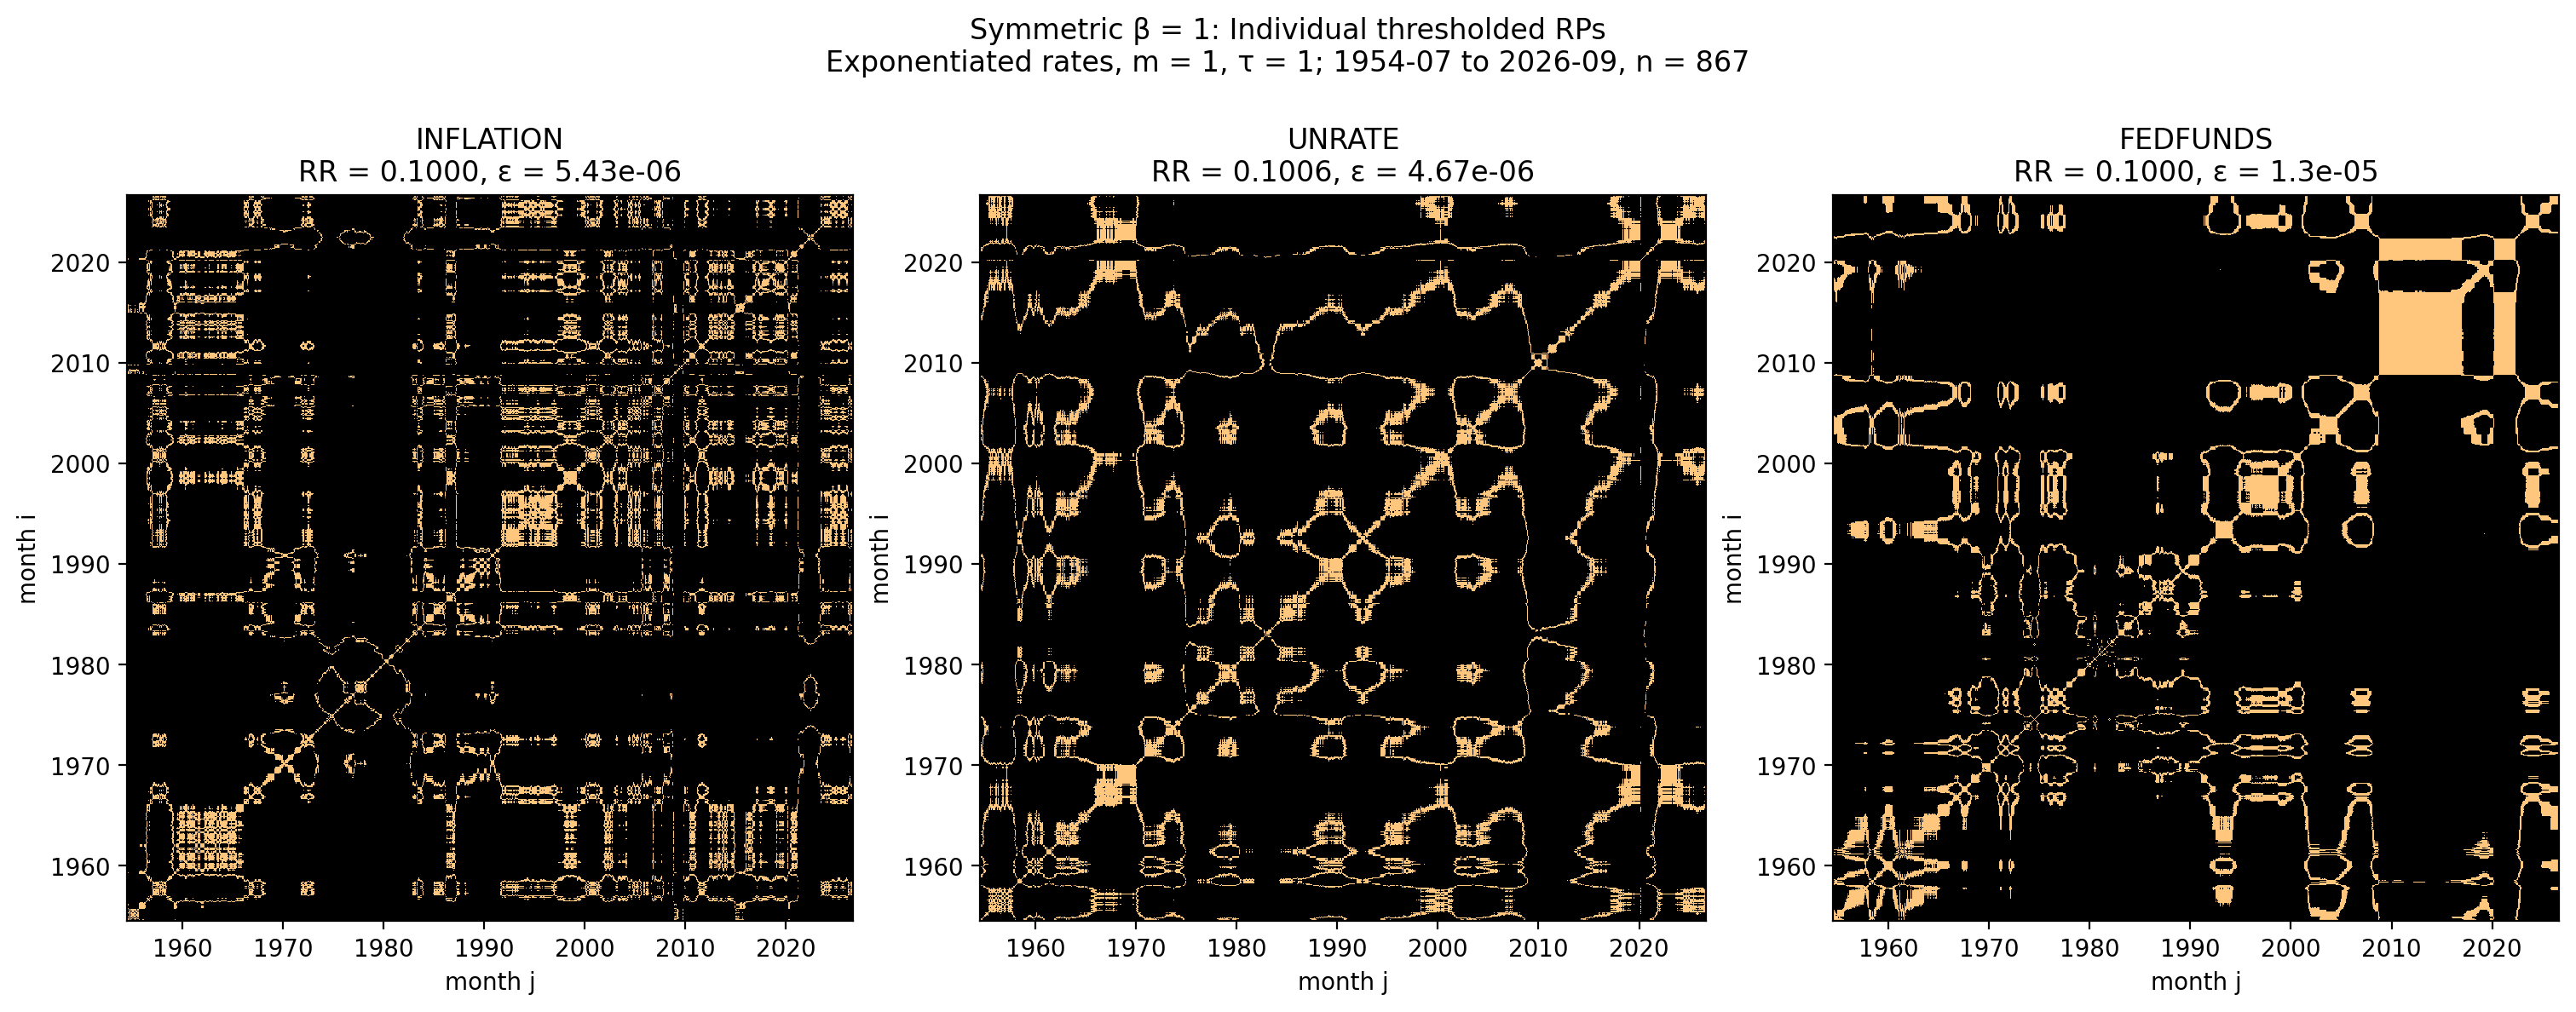

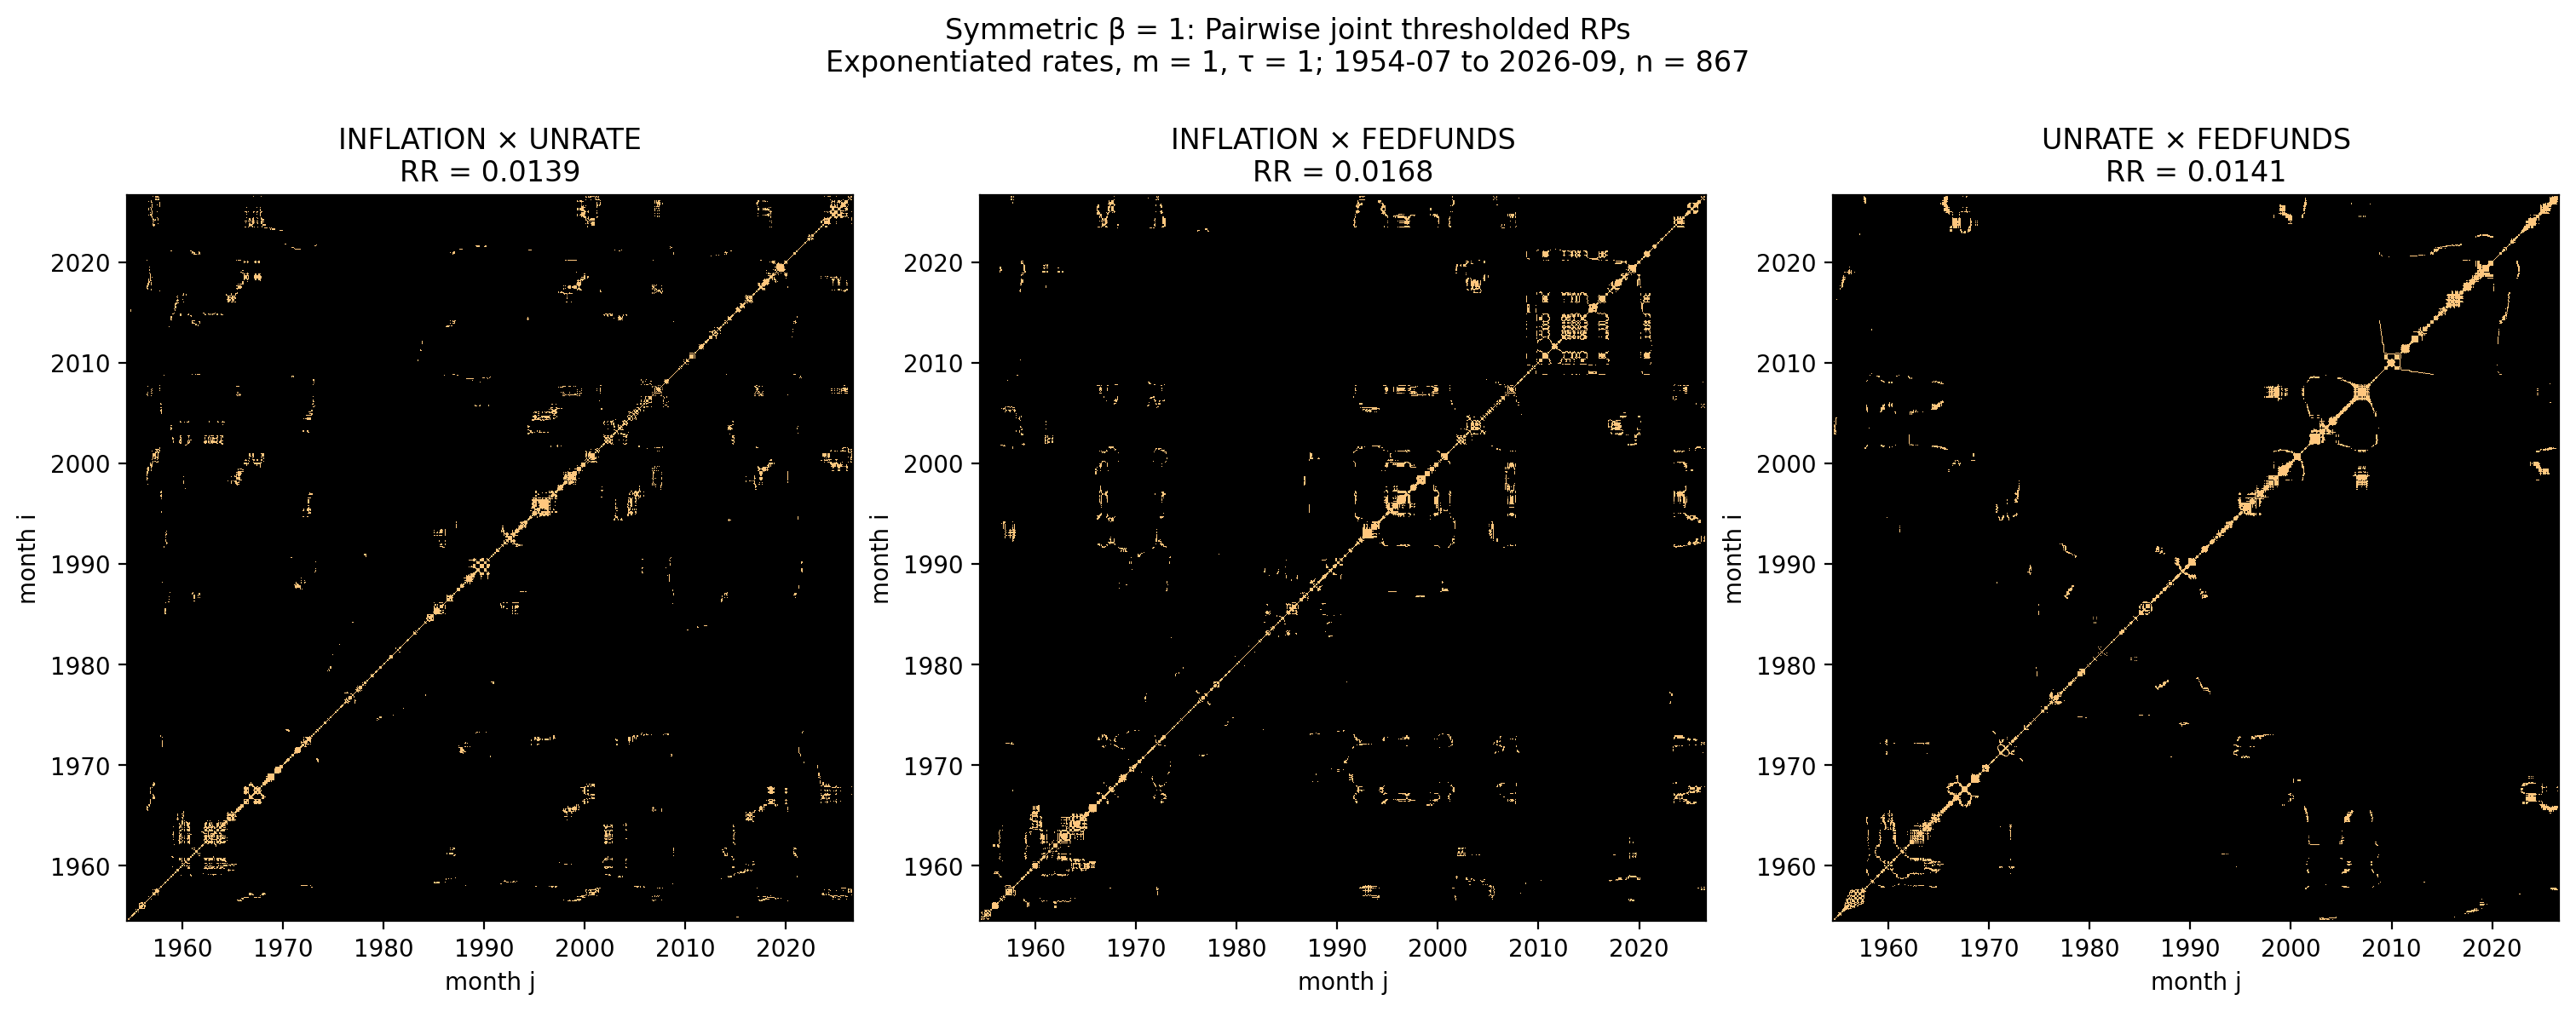

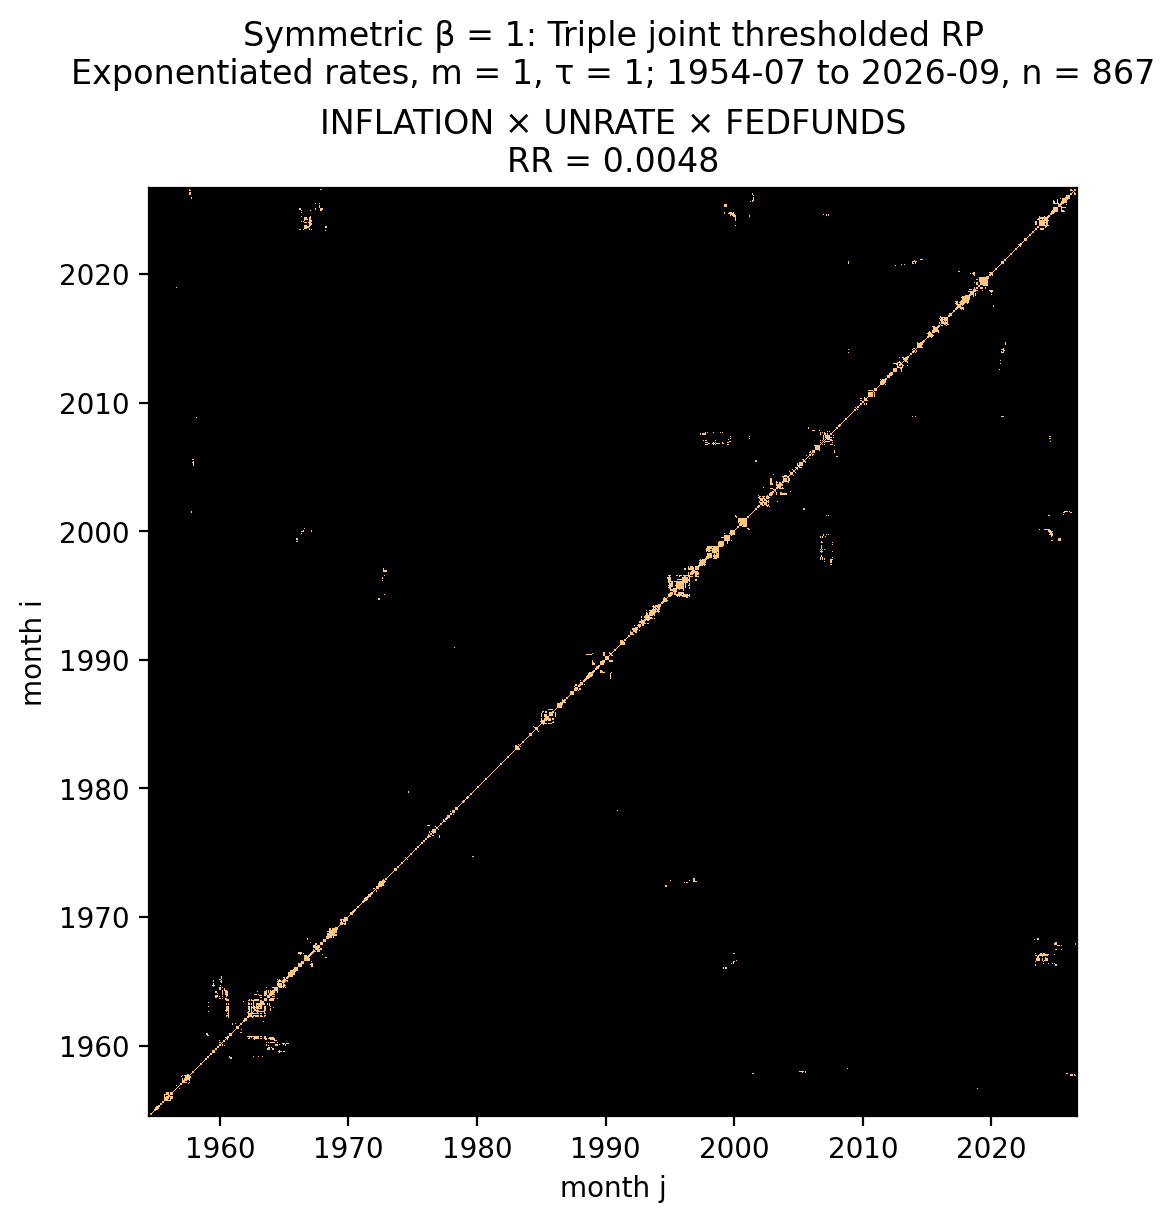

In [56]:
beta_results[1] = plot_beta_rps(1)


### β = 3


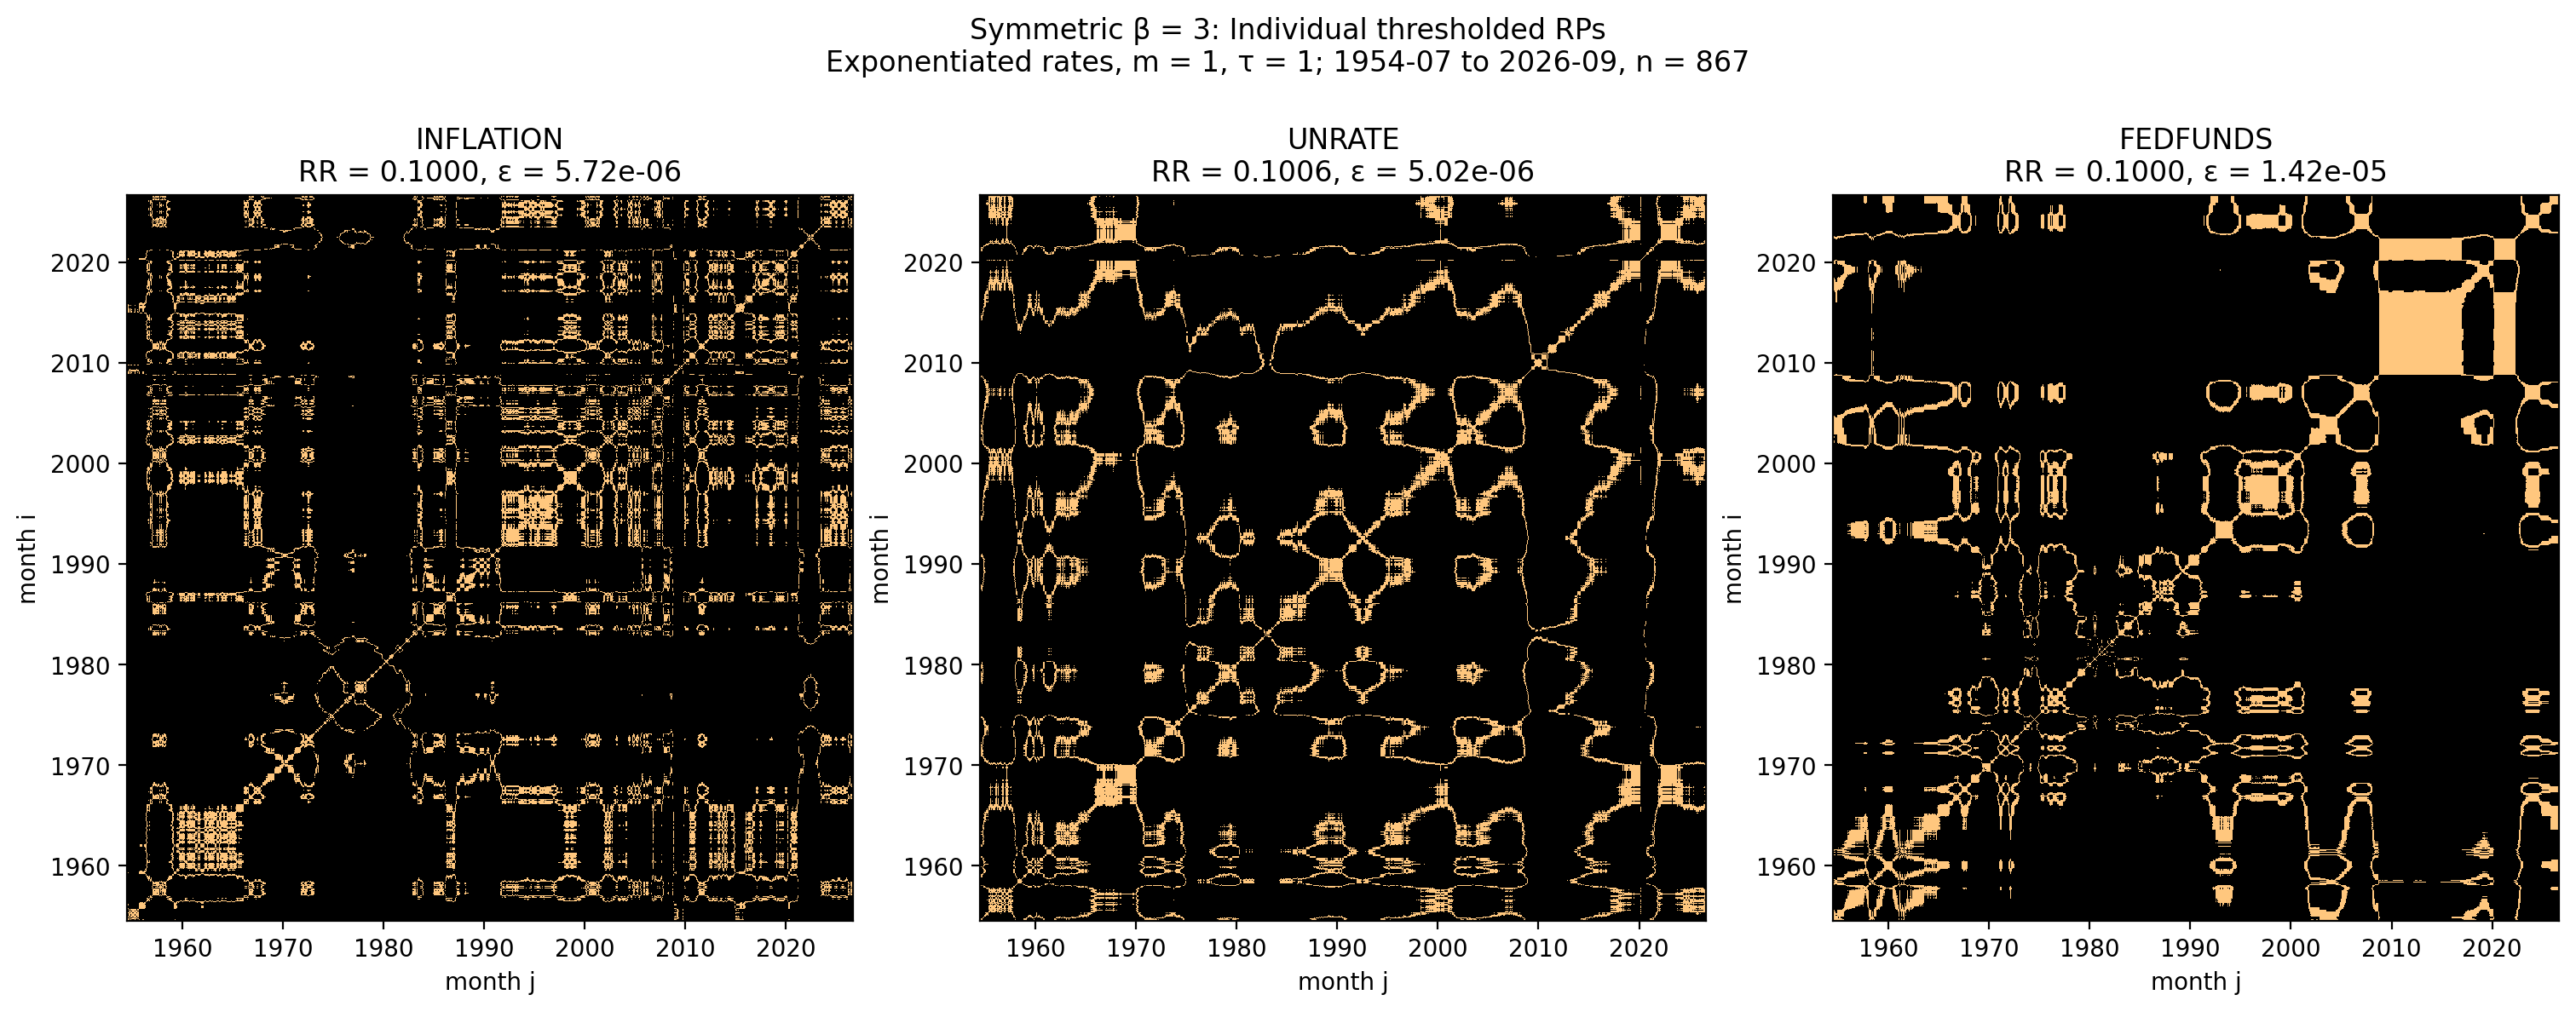

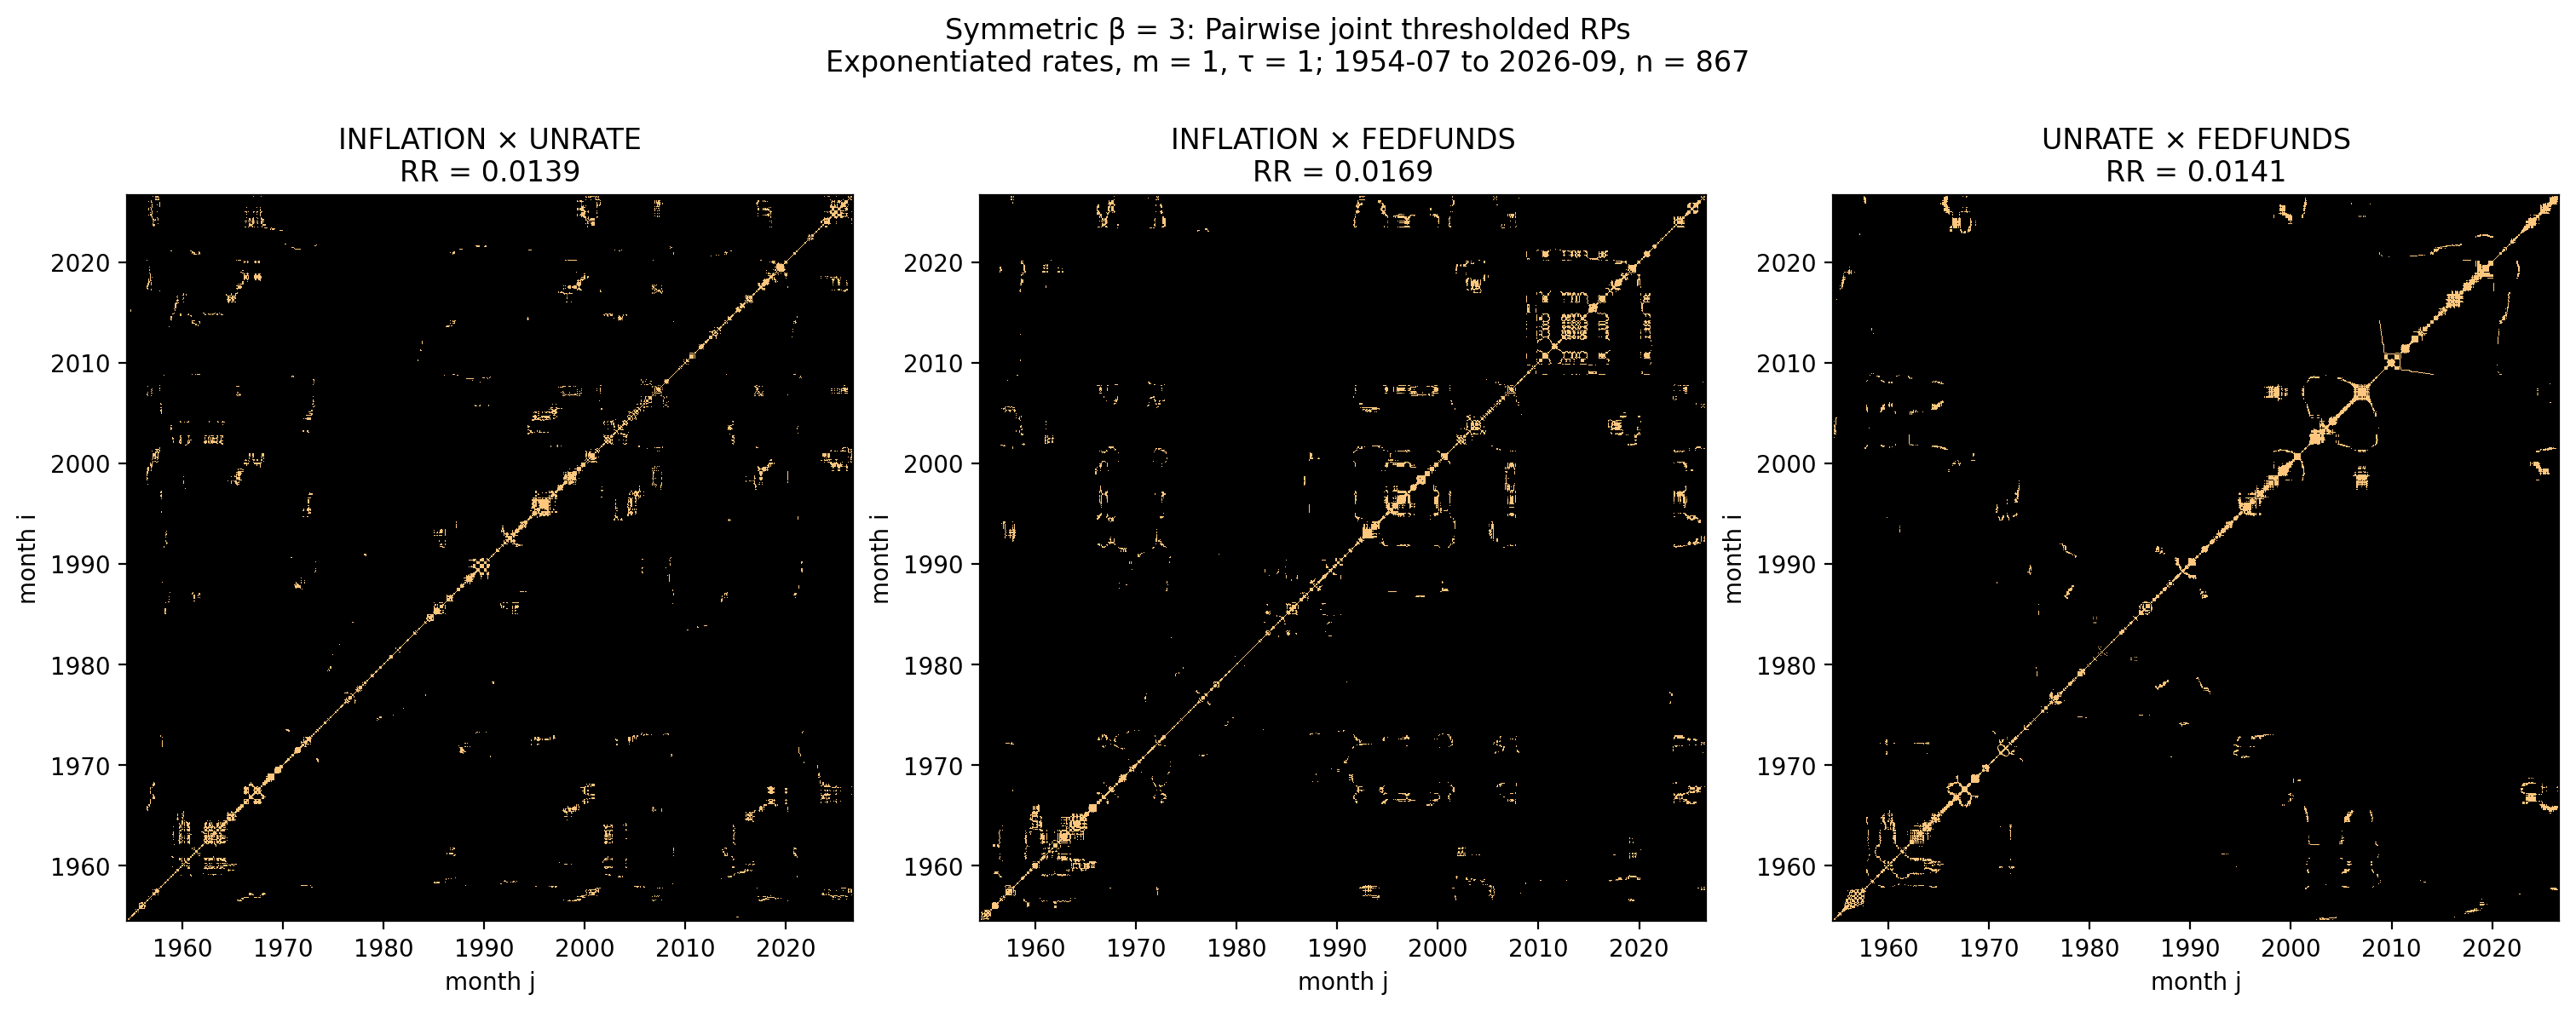

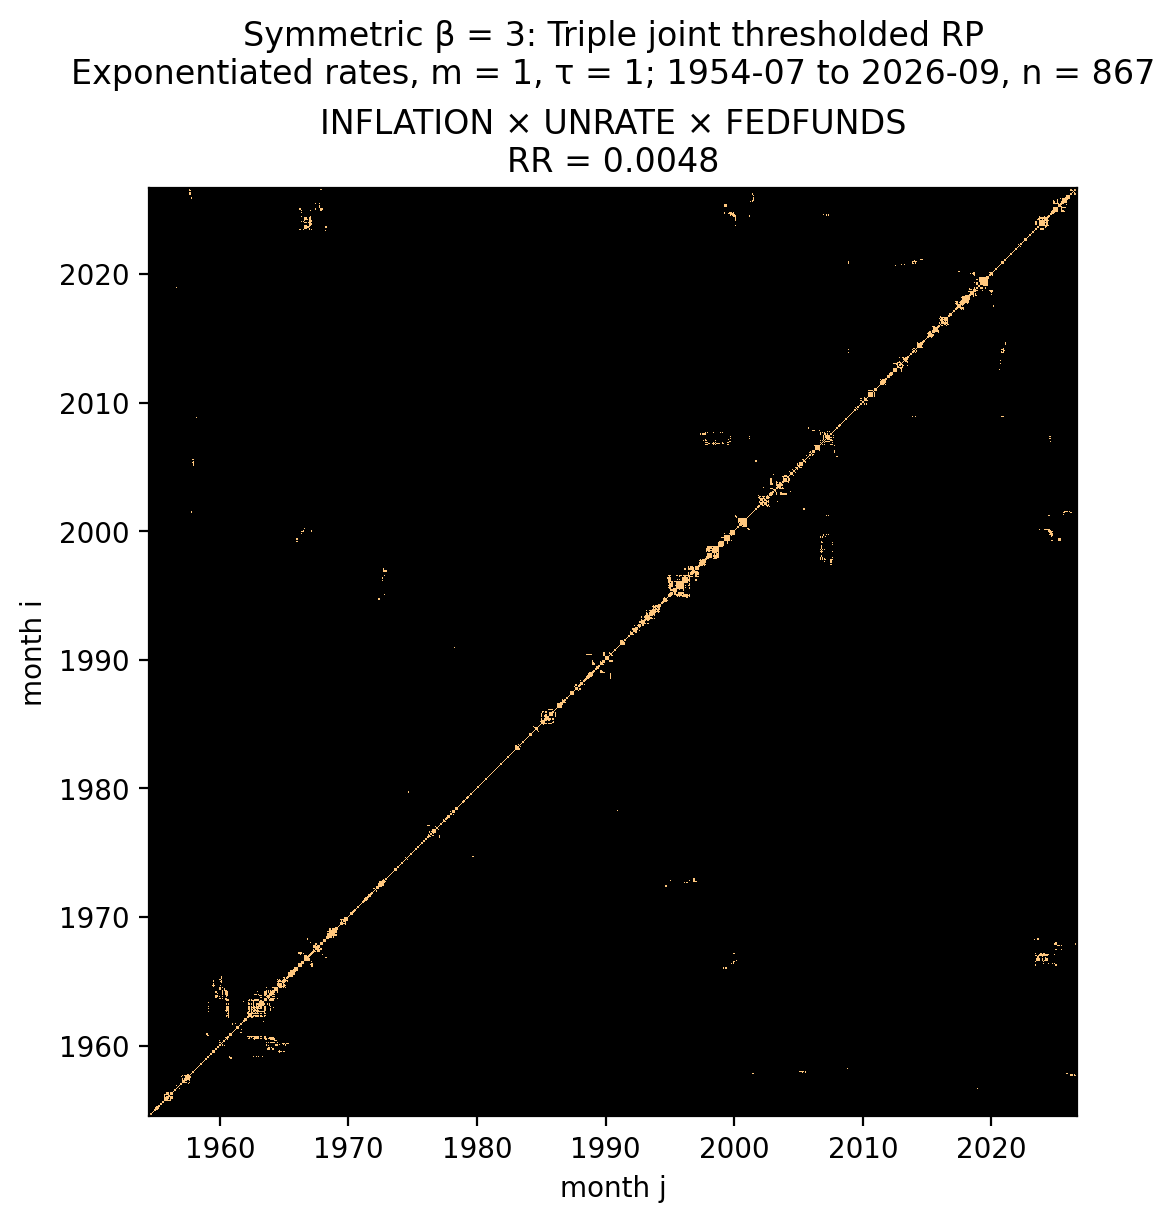

In [57]:
beta_results[3] = plot_beta_rps(3)


### β = 7


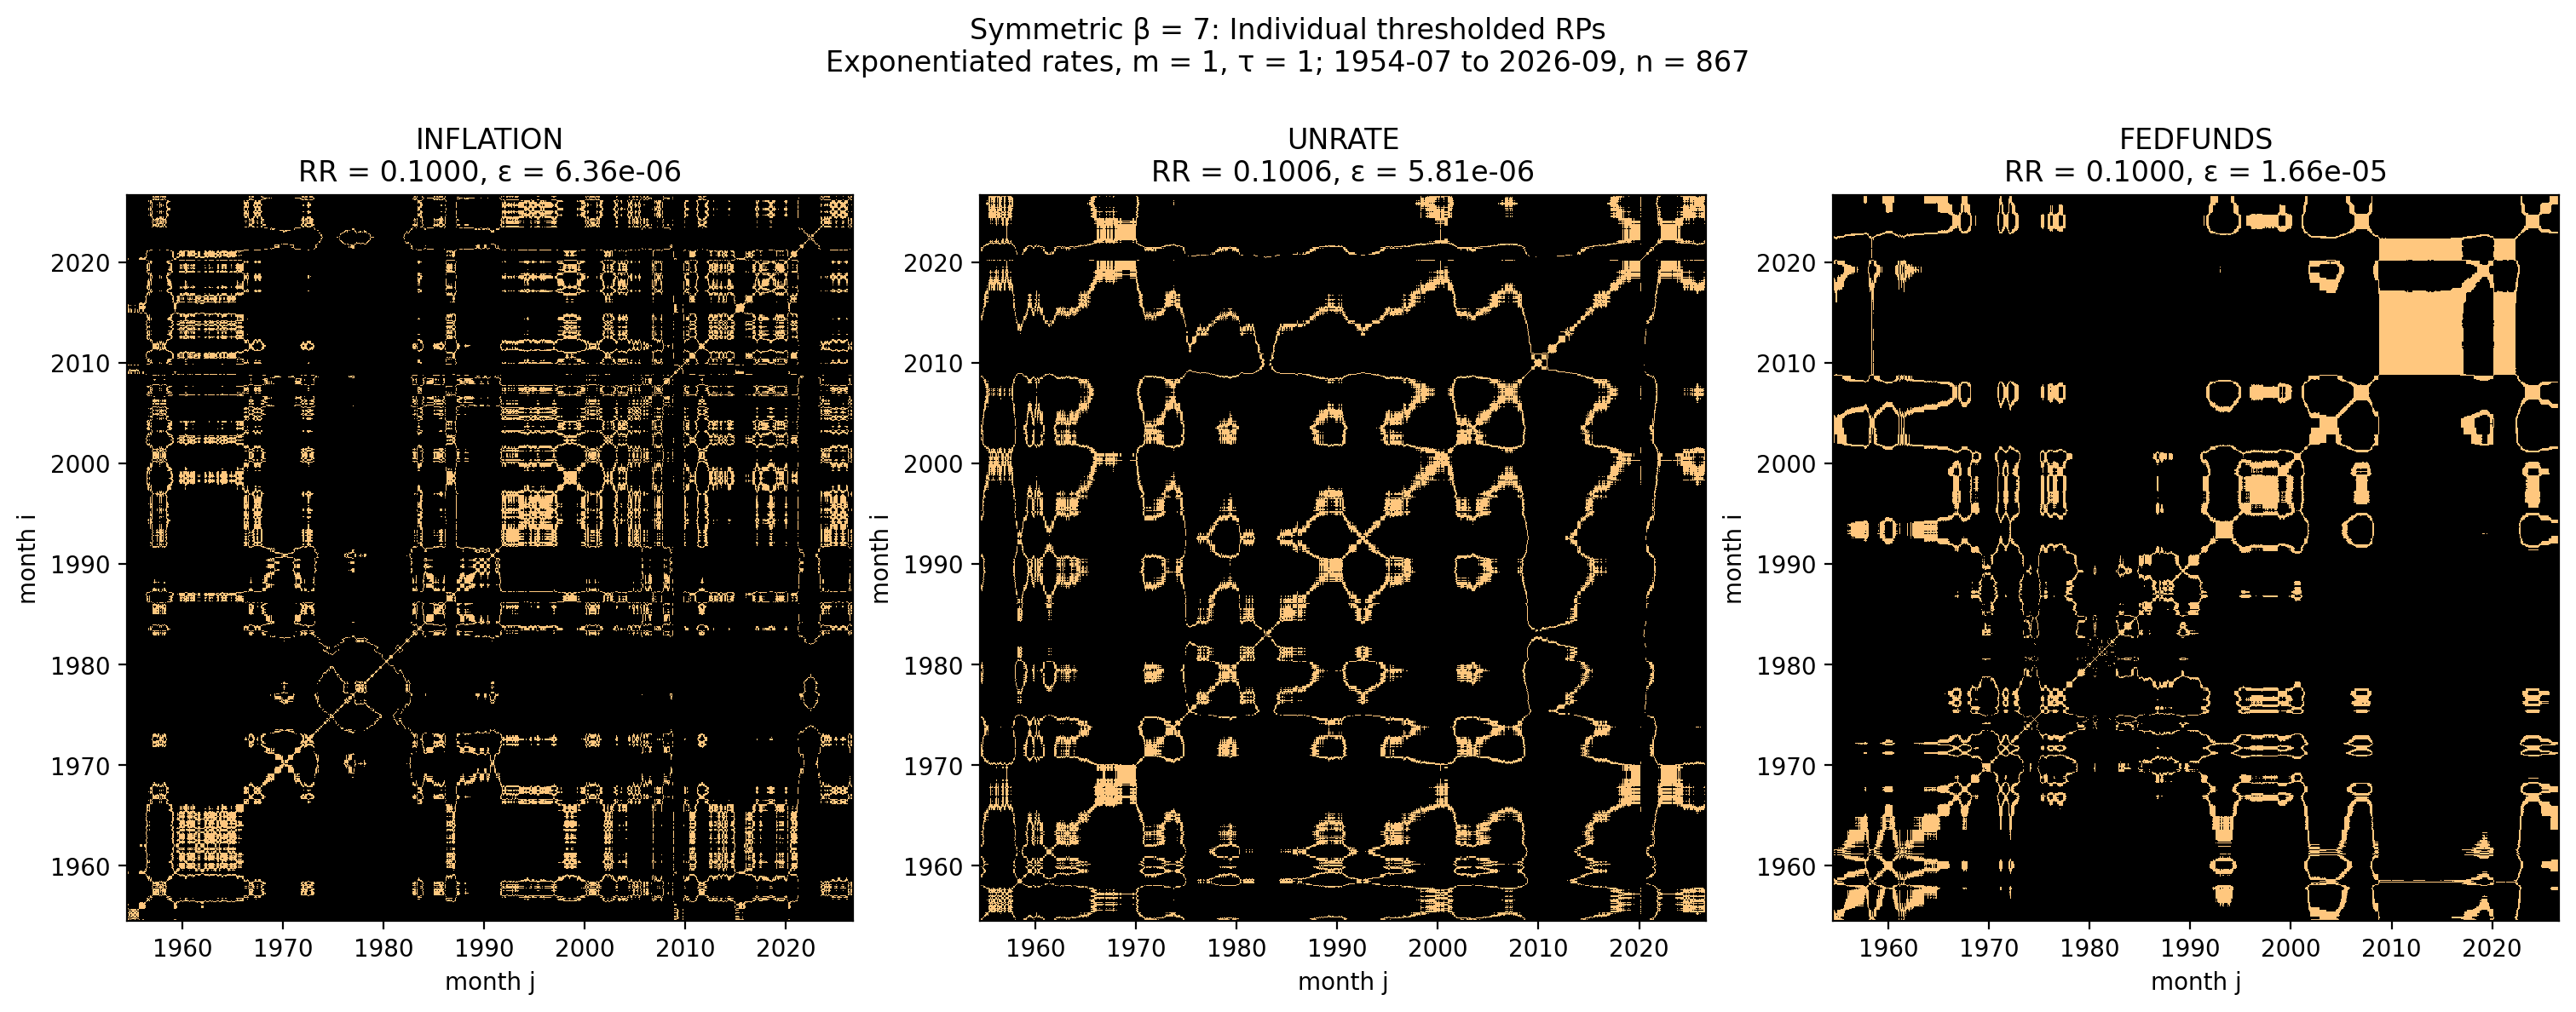

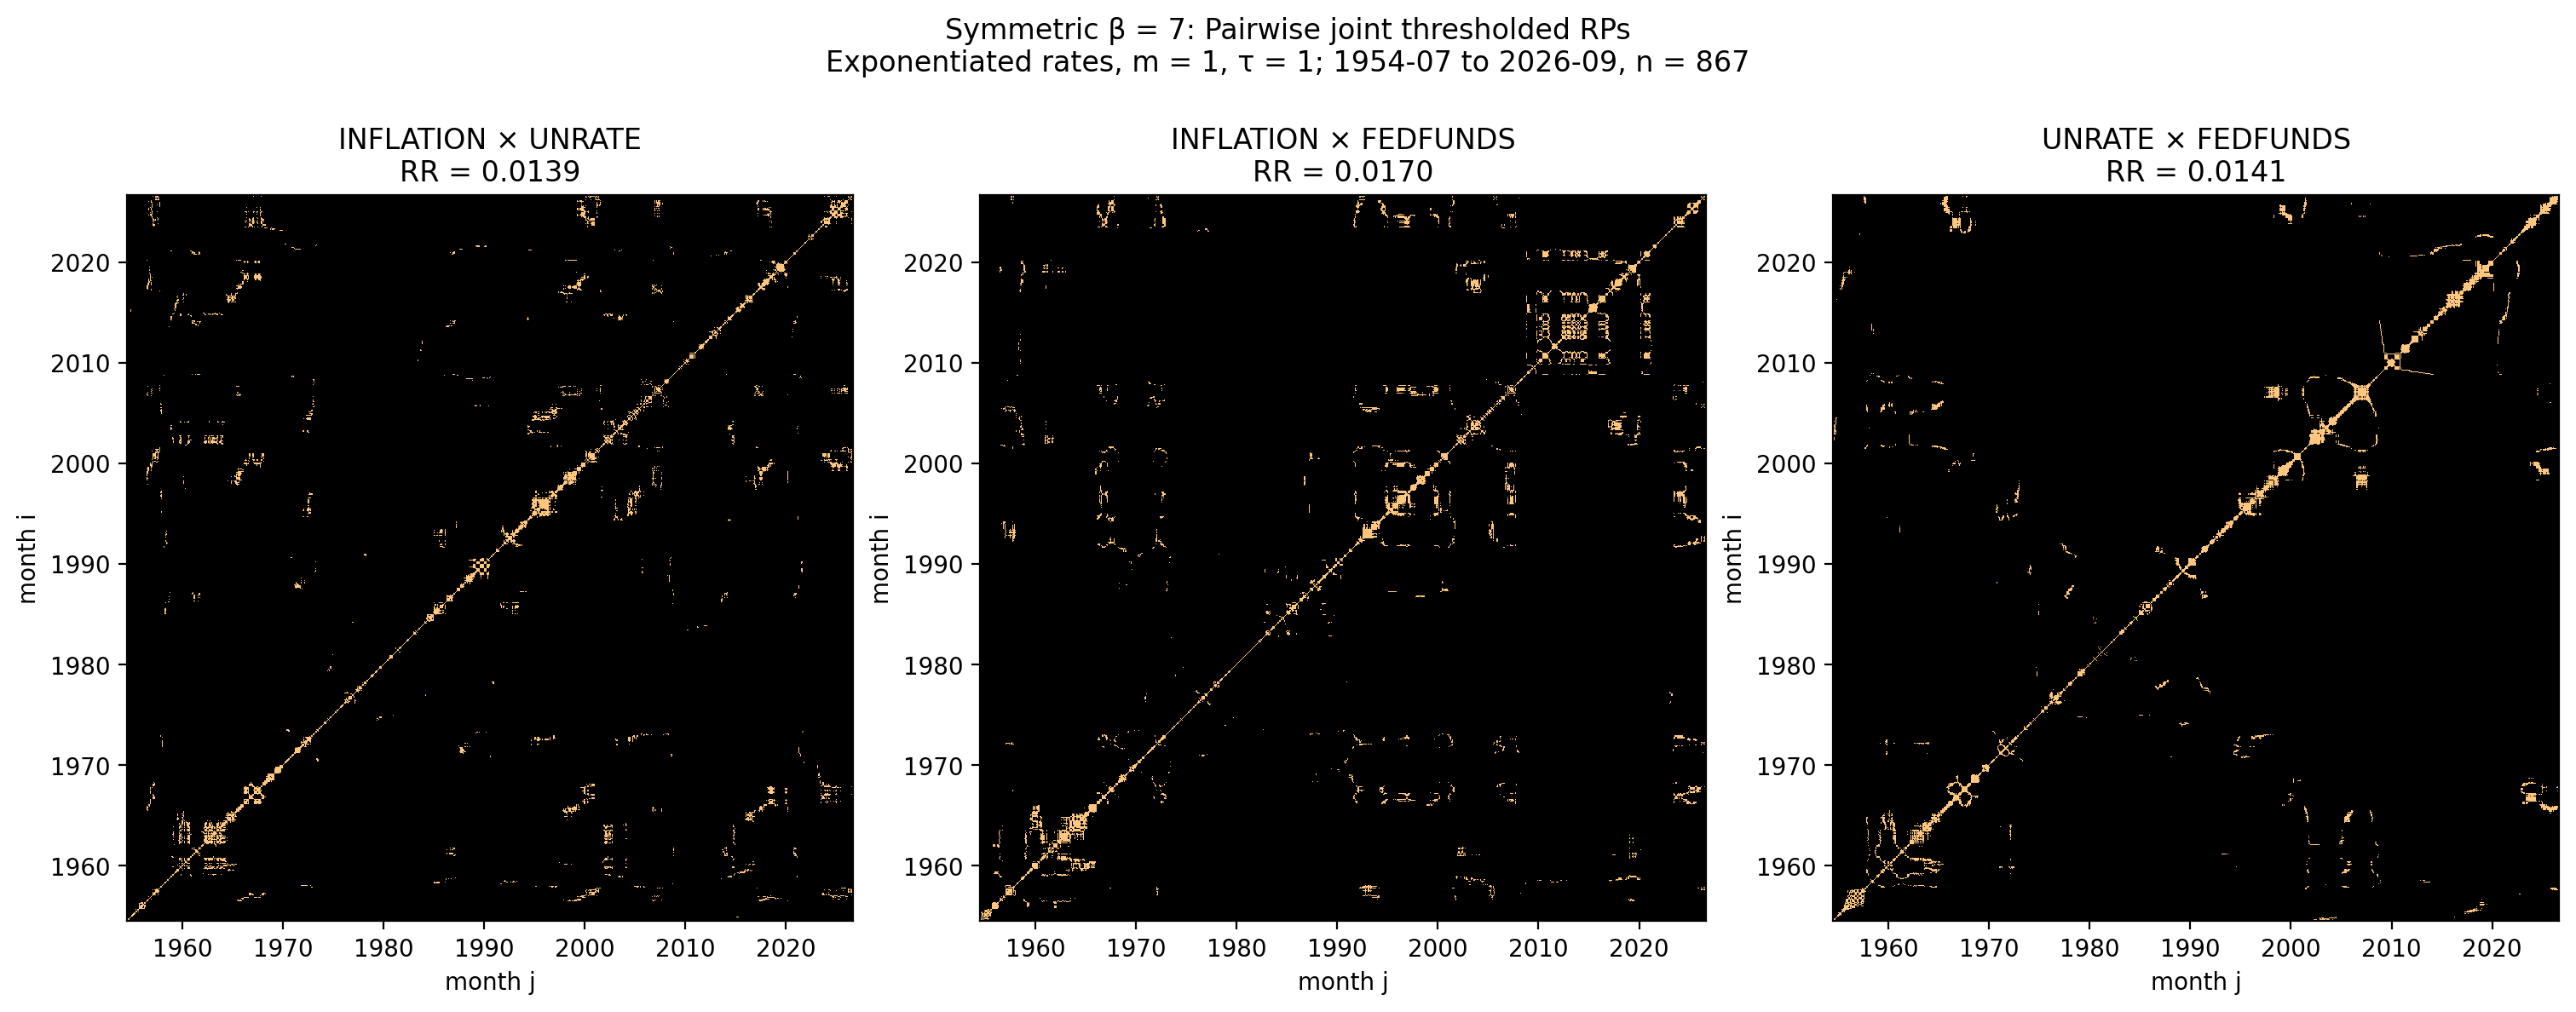

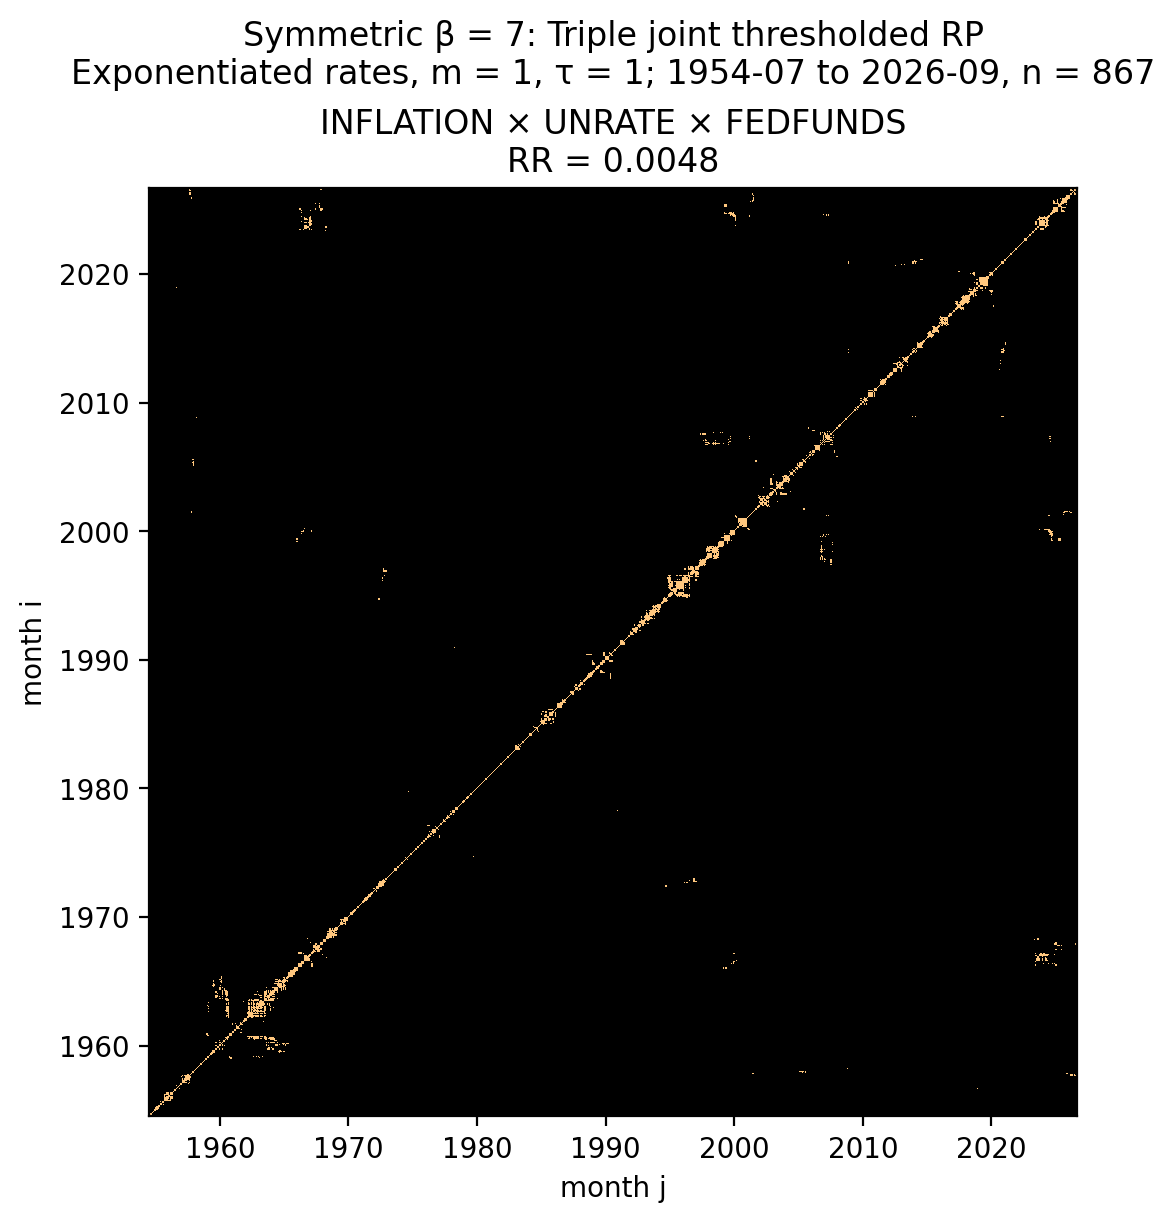

In [58]:
beta_results[7] = plot_beta_rps(7)